# A02 Final Project: Healthcare Equity Across the U.S. - Hospital Readmission Rates and Insurance Coverage

Cohort A | Team 02

Aqsa Siddique | Samarth Karan | Ting Hui Chu | Dhruv Shah

**Data sources**

| Dataset | Publisher | Link |
|---|---|---|
| Unplanned Hospital Visits – Hospital | CMS Provider Data Catalog | https://data.cms.gov/provider-data/dataset/632h-zaca |
| Unplanned Hospital Visits – State | CMS Provider Data Catalog | https://data.cms.gov/provider-data/dataset/4gkm-5ypv |
| Health Insurance Coverage of the Total Population, 2022–2024 | KFF State Health Facts | https://www.kff.org/state-health-policy-data/state-indicator/total-population/ |
| Status of State Medicaid Expansion Decisions (published October 2026) | KFF | https://www.kff.org/status-of-state-medicaid-expansion-decisions/ |
| Status of State Action on the Medicaid Expansion Decision (as of October 2026) | KFF State Health Facts | https://www.kff.org/affordable-care-act/state-indicator/state-activity-around-expanding-medicaid-under-the-affordable-care-act/ |

**License:** CMS data are U.S. government public data. KFF data are used under KFF's terms of use with attribution.

**Access:** Each CSV can be downloaded from the links above. This notebook loads copies of the five files from shared Google Drive links, so it runs in Colab with no local file paths.

## Problem Definition and the Decision It Informs

**Business Question:** Should a State Medicaid agency or hospital association fund coverage expansion to cut 30-day hospital readmissions and the CMS penalties tied to them, or put that money into care-transition programs?

Under the Hospital Readmissions Reduction Program, CMS lowers payments to hospitals whose readmission rates are higher than expected. A common argument is that uninsured patients get less follow-up care and are readmitted more often. If that holds at the state level, states with more uninsured residents, and states that did not expand Medicaid, should show worse readmission results. We test that across 52 geographies.

**Stakeholders:** State Medicaid Agencies (expansion and outreach), Hospital Associations (discharge and follow-up investment) and CMS (quality reporting).

**What changed since the Team Assignment:** The Team Assignment showed that the data are usable and that both variables vary across states. This phase joins the two sources state by state and tests whether they move together, using hypotheses, robustness check, exploratory regression, and supporting analysis. Decision rules were fixed before the final run.

## Executive Summary

**Objective** Should a state fund coverage expansion to reduce 30-day hospital readmissions, or fund care-transition programs?

**Methods** 14,701 usable CMS hospital-condition records (Jul 2023 to Jun 2025), each compared with the national median for the same condition, summarized by state and joined to KFF coverage (2023-2024 average) for 52 geographies. Correlations, t-tests with effect sizes, Holm correction for secondary tests, and one exploratory regression.

**Key Findings**
- **Primary Test H6 (Not Supported):** The uninsured rate is not linked to a state's readmission gap (r = −0.11, 95% CI [−0.37, +0.17]). Same without Puerto Rico (r = −0.08).
- **Primary Test H7 (Not Supported):** Expansion and non-expansion states have almost identical gaps (difference −0.01 percentage points, Cohen's d = −0.07, p = 0.40).
- **Expansion does lower uninsured rates (H5):** 6.72% in expansion states vs. 9.96% in non-expansion states (d = −1.41), yet this does not show up in readmissions (H7).
- **Gaps are consistent within a state (H13):** a state above the national rate on one medical condition tends to be above on the others (average r = +0.61), which is where care-transition programs would be aimed.
- **Why:** State gaps span only 1.20 percentage points, while uninsured rates differ 6.2-fold (Massachusetts 2.69% vs. Texas 16.56%).
- **One association held up:** A larger Medicaid share goes with higher gaps (H10: r = +0.45, Holm p = 0.0014), but Puerto Rico drives much of it (r = +0.25 without it), and Medicaid share may mainly reflect poverty.

**Recommendations** Judge coverage expansion on access and financial protection grounds, not as a readmission program. To reduce readmissions, consider care transition programs (discharge planning, follow-up calls, medication reconciliation) aimed at states with persistently above national gaps.

*We did not test those programs. The recommendation rests on the absence of a coverage effect and on published evidence (references 8 and 9).*

**Caveat:** CMS scores come from Medicare patients and KFF coverage describes everyone, so a null result means "no evidence through this state-level proxy", not "insurance does not matter". **Next step:** patient-level data and a fuller model.

## Recap of the Team Assignment

**Data:** 67,060 raw CMS rows; 28,740 are readmission rows; 14,701 (51.2%) have a usable score and 14,039 were suppressed by CMS for small case counts.

**Cleaning:** Text scores converted to numbers; KFF head counts turned into shares; CMS state codes matched to KFF names (52 geographies in both sources).

**Findings carried forward:** Condition drives raw scores (H1), state gaps are narrow (H2) while uninsured rates differ widely (H3), CABG has fewer than 1,000 usable records (H4).

**Left open then, tested here:** Whether uninsured rates line up with readmission gaps (H6 onward). The Team Assignment's hypotheses map to H4, H1, H2, H3 and H6 here. Its coverage trend hypothesis (uninsured rates rose slightly from 2022 to 2024) is replaced by H5, which checks that Medicaid expansion actually goes with lower uninsured rates, because that link matters more for the readmission question.

**Changes from the proposal** Two things changed after the proposal. First, we narrowed the hospital data to the six 30-day readmission measures and matched 52 geographies (50 states, DC and Puerto Rico), because CMS and KFF align on those. Second, CMS reports one pooled period (July 2023 to June 2025), so we compared it with the 2023-2024 average of KFF coverage instead of matching year by year. We also added tests the proposal did not list: Medicaid-expansion status, Medicaid share, hospital volume and a multivariable check.

## 1. Setting Up

In [ ]:
# Setup (Run Me First): libraries, color palette and three small statistics helpers
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

np.random.seed(42)

# Purple color palette for all charts
PURPLE = "#6A0DAD"
DARK_PURPLE = "#4B0082"
MEDIUM_PURPLE = "#8E44AD"
LIGHT_PURPLE = "#B57EDC"
PALE_PURPLE = "#D8B4E2"
GRAY = "#7F7F7F"


def cohens_d(a, b):
    """Standardized mean difference between two groups (pooled SD)."""
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1))
                     / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled


def r_ci(r, n):
    """95% confidence interval for a Pearson r (Fisher z)."""
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    return np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)


def one_sided(p_two, stat, expect_positive=True):
    """Convert a two-sided p-value to one-sided, given the direction we predicted."""
    right_direction = stat > 0 if expect_positive else stat < 0
    return p_two / 2 if right_direction else 1 - p_two / 2


# One row per hypothesis is added here as we go. Section 11 turns it into the results table
results = []

## 2. Data Loading and Cleaning (Team Assignment)

This section repeats the Team Assignment. The full step-by-step inspection was submitted with the Team Assignment.

In [ ]:
health_insurance_2022 = pd.read_csv("https://drive.google.com/uc?export=download&id=1D7U4cjPLlM7KTs5gu9NdZQloMEMiCdFP", skiprows=2)
health_insurance_2023 = pd.read_csv("https://drive.google.com/uc?export=download&id=1N9cML9hD-n5QcuuABZZJa0Ggv-j6o2g3", skiprows=2)
health_insurance_2024 = pd.read_csv("https://drive.google.com/uc?export=download&id=1f4NybYKcXIk5VKk2A8AfURcpFcT5oOK-", skiprows=2)
unplanned_visit_hp = pd.read_csv("https://drive.google.com/uc?export=download&id=1d1arWpbkw1ioPijTXqpdvQXGSTlCxR3X", low_memory=False)
unplanned_visit_st = pd.read_csv("https://drive.google.com/uc?export=download&id=1jD_oxytd4u9qyyoqhUKyVoVmTG1afq0W", low_memory=False)

# Quick look at the raw files
for name, df in {"KFF 2022": health_insurance_2022, "KFF 2023": health_insurance_2023,
                 "KFF 2024": health_insurance_2024, "CMS hospital": unplanned_visit_hp,
                 "CMS state": unplanned_visit_st}.items():
    print(f"{name:13s}: {df.shape[0]:>6,} rows x {df.shape[1]} columns")

KFF 2022     :    106 rows x 9 columns
KFF 2023     :    106 rows x 9 columns
KFF 2024     :    106 rows x 9 columns
CMS hospital : 67,060 rows x 20 columns
CMS state    :    784 rows x 14 columns


### Hospital-Level Readmission Scores (CMS)

In [ ]:
hospital = unplanned_visit_hp.copy()
hospital.columns = hospital.columns.str.strip()
hospital["State"] = hospital["State"].str.strip()
hospital["Measure ID"] = hospital["Measure ID"].str.strip()

# Keep the six 30-day readmission measures
readmission_measures = ["READM_30_AMI", "READM_30_HF", "READM_30_PN",
                        "READM_30_COPD", "READM_30_CABG", "READM_30_HIP_KNEE"]
hospital = hospital[hospital["Measure ID"].isin(readmission_measures)].copy()

# Score and Denominator are text ("Not Available"); convert to numbers, text becomes NaN
print("Text values in Score:", hospital.loc[pd.to_numeric(hospital["Score"], errors="coerce").isnull(), "Score"].value_counts().to_dict())
hospital["Score"] = pd.to_numeric(hospital["Score"], errors="coerce")
hospital["Denominator"] = pd.to_numeric(hospital["Denominator"], errors="coerce")
hospital["Start Date"] = pd.to_datetime(hospital["Start Date"], errors="coerce")
hospital["End Date"] = pd.to_datetime(hospital["End Date"], errors="coerce")

# Analysis rows: a reported score and a positive denominator
hospital_valid = hospital.dropna(subset=["Score", "Denominator"]).copy()
hospital_valid = hospital_valid[hospital_valid["Denominator"] > 0].copy()

excluded = len(hospital) - len(hospital_valid)
print(f"Readmission Rows: {len(hospital):,} | Usable: {len(hospital_valid):,} ({len(hospital_valid) / len(hospital):.1%}) | "
      f"Suppressed: {excluded:,} ({excluded / len(hospital):.1%})")
print("Reporting Period:", hospital_valid["Start Date"].min().date(), "to", hospital_valid["End Date"].max().date())

measure_names = {
    "READM_30_AMI": "Heart Attack (AMI)", "READM_30_HF": "Heart Failure",
    "READM_30_PN": "Pneumonia", "READM_30_COPD": "COPD",
    "READM_30_CABG": "CABG Surgery", "READM_30_HIP_KNEE": "Hip/Knee Replacement"
}
hospital_valid["Measure Label"] = hospital_valid["Measure ID"].map(measure_names)

Text values in Score: {'Not Available': 14039}
Readmission Rows: 28,740 | Usable: 14,701 (51.2%) | Suppressed: 14,039 (48.8%)
Reporting Period: 2023-07-01 to 2025-06-30


**Takeaway:** 14,701 of 28,740 readmission records (51.2%) have a usable score. The other 14,039 are "Not Available" because CMS suppresses scores for hospitals with too few cases. All scores cover the same pooled period, July 2023 to June 2025.

### State-Level Hospital Classifications (CMS)

In [ ]:
state = unplanned_visit_st.copy()
state.columns = state.columns.str.strip()

state_numeric_columns = ["Number of Hospitals Worse", "Number of Hospitals Same",
                         "Number of Hospitals Better", "Number of Hospitals Too Few"]
for column in state_numeric_columns:
    state[column] = pd.to_numeric(state[column], errors="coerce")   # "Not Applicable" -> NaN

# Readmission rows use Worse/Same/Better/Too Few; other measures leave these columns empty
state[state["Measure ID"].str.startswith("READM_30_")][["State", "Measure ID"] + state_numeric_columns].head(3)

,State,Measure ID,Number of Hospitals Worse,Number of Hospitals Same,Number of Hospitals Better,Number of Hospitals Too Few
8,AK,READM_30_AMI,0.0,4.0,0.0,11.0
9,AK,READM_30_CABG,0.0,1.0,0.0,2.0
10,AK,READM_30_COPD,0.0,8.0,0.0,13.0


**Takeaway:** The state file reports, for each state and condition, how many hospitals CMS rates worse than, the same as, or better than the national rate. We use it only as an independent check on our own gap measure (H6b).

### State Insurance Coverage (KFF)

In [ ]:
def clean_kff(df, year):
    """Clean one year of KFF insurance data and add a Year column."""
    df = df.copy()
    df.columns = df.columns.str.strip()
    df = df.rename(columns={"Location": "State"})

    required_columns = ["State", "Employer", "Non-Group", "Medicaid",
                        "Medicare", "Military", "Uninsured", "Total"]
    missing_columns = set(required_columns) - set(df.columns)
    if missing_columns:
        raise ValueError(f"{year} KFF file is missing columns: {missing_columns}")

    df["State"] = df["State"].str.strip()
    for col in required_columns[1:]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["Year"] = year
    return df[required_columns + ["Year"]]


insurance = pd.concat([clean_kff(health_insurance_2022, 2022),
                       clean_kff(health_insurance_2023, 2023),
                       clean_kff(health_insurance_2024, 2024)], ignore_index=True)

# Drop KFF note rows (no Total) and the national total
insurance = insurance.dropna(subset=["State", "Total"])
insurance = insurance[insurance["State"] != "United States"].copy()

# Head counts mostly reflect state size, so convert to % of each state's population
coverage_columns = {"Employer": "Employer_%", "Non-Group": "Non_Group_%", "Medicaid": "Medicaid_%",
                    "Medicare": "Medicare_%", "Military": "Military_%", "Uninsured": "Uninsured_%"}
for source_col, output_col in coverage_columns.items():
    insurance[output_col] = insurance[source_col] / insurance["Total"] * 100

display(insurance.groupby("Year")["State"].count().to_frame("States"))
insurance[list(coverage_columns.values())].describe().round(2)

,States
Year,
2022,52
2023,52
2024,52


,Employer_%,Non_Group_%,Medicaid_%,Medicare_%,Military_%,Uninsured_%
count,156.00,156.00,156.00,156.00,156.00,156.00
mean,48.74,6.12,20.91,15.43,1.50,7.30
std,6.01,1.56,5.92,2.19,0.94,2.65
min,22.73,2.84,10.20,8.03,0.33,2.42
25%,46.44,5.17,17.94,14.37,0.81,5.43
50%,49.36,5.70,20.28,15.56,1.39,6.81
75%,52.70,6.87,22.87,16.63,1.89,9.01
max,60.38,12.55,47.06,19.53,5.90,16.77


**Takeaway:** Each year has exactly 52 geographies (50 states, DC and Puerto Rico), giving 156 state-year rows. Shares are used instead of head counts, because a head count mostly reflects how big a state is.

### Matching State Names and Adding Medicaid Expansion Status

In [ ]:
# State lookup table from the course repository (09-Joins-and-APIs, US States exercise) + Puerto Rico
abbrevs = pd.read_csv("https://raw.githubusercontent.com/soltaniehha/Business-Analytics/master/data/state-abbrevs.csv")
abbrevs = pd.concat([abbrevs, pd.DataFrame({"state": ["Puerto Rico"], "abbreviation": ["PR"]})],
                    ignore_index=True)
state_abbrev_to_name = dict(zip(abbrevs["abbreviation"], abbrevs["state"]))

hospital_valid = pd.merge(hospital_valid, abbrevs, how="left", left_on="State",
                          right_on="abbreviation", validate="many_to_one")
hospital_valid = hospital_valid.rename(columns={"state": "State_Name"}).drop(columns="abbreviation")
state["State_Name"] = state["State"].map(state_abbrev_to_name)

# Do CMS and KFF cover the same places?
check = pd.merge(pd.DataFrame({"State_Name": hospital_valid["State_Name"].dropna().unique()}),
                 pd.DataFrame({"State_Name": insurance["State"].unique()}),
                 on="State_Name", how="outer", indicator=True)
print(check["_merge"].value_counts().to_dict())
print("CMS codes without a KFF match (dropped):",
      sorted(hospital_valid.loc[hospital_valid["State_Name"].isnull(), "State"].unique()))

# Medicaid expansion: the 10 states that have NOT adopted it (KFF, as of October 2026).
# Puerto Rico is outside the ACA expansion framework and is excluded from expansion tests (H7, H9).
non_expansion_states = ["Alabama", "Florida", "Georgia", "Kansas", "Mississippi",
                        "South Carolina", "Tennessee", "Texas", "Wisconsin", "Wyoming"]

{'both': 52, 'left_only': 0, 'right_only': 0}
CMS codes without a KFF match (dropped): ['GU', 'MP', 'VI']


**Takeaway:** CMS and KFF match on all 52 geographies. Guam, the Northern Mariana Islands and the U.S. Virgin Islands appear only in CMS and are dropped. Expansion status comes from KFF's list of the 10 non-adopting states.

**Why Puerto Rico stays in, and where it is excluded.** The analysis covers **52 geographies: 50 states, the District of Columbia and Puerto Rico** (we call them "states" only for short). Puerto Rico is in both CMS and KFF, and its hospitals are scored under the same readmission program, so it is kept in the descriptive work (H1 to H4, H6, H6b, H8, H10, H11, H13). It is excluded where it does not fit the question: H5, H7, H9 and H12 depend on the ACA Medicaid-expansion decision, which does not apply to Puerto Rico. Since it is an outlier on Medicaid share (47.0%, next highest 33.7%), H6 and H10 are also reported without it. Guam, the Northern Mariana Islands and the U.S. Virgin Islands appear only in CMS and are dropped. The "Puerto Rico check" table in Section 10 shows that no verdict changes without it. Only the sizes of the H2 range and the H10 correlation shrink. Puerto Rico is labelled by name in the charts where it stands out (Charts 2, 12), so stakeholders can see it rather than have it silently removed.


## 3. Data Dictionary

**Fields Used from the Raw Files**

| Dataset | Field | Type | Description |
|---|---|---|---|
| CMS hospital | `Facility ID` | text | Unique hospital identifier |
| CMS hospital | `State` | text | Two-letter state code (e.g. MA) |
| CMS hospital | `Measure ID` | text | Measure code; we keep the six `READM_30_*` readmission measures |
| CMS hospital | `Score` | number (stored as text) | Risk-standardized 30-day readmission rate for that hospital and condition (%); "Not Available" when suppressed |
| CMS hospital | `Denominator` | number (stored as text) | Number of eligible patient discharges behind the score (hospital volume) |
| CMS hospital | `Start Date`, `End Date` | date | Reporting window (07/01/2023 to 06/30/2025 for all readmission measures) |
| CMS state | `Number of Hospitals Worse / Same / Better / Too Few` | number (stored as text) | Hospitals in the state that CMS rates worse than, the same as, or better than the national rate, or has too few cases to rate |
| KFF (2022–2024) | `Location` | text | State name (renamed to `State`) |
| KFF (2022–2024) | `Employer`, `Non-Group`, `Medicaid`, `Medicare`, `Military`, `Uninsured` | number | Number of residents by main source of coverage |
| KFF (2022–2024) | `Total` | number | Total state population |

**Fields We Created**

| Field | Table | Description |
|---|---|---|
| `Measure Label` | `hospital_valid` | Readable condition name (e.g. Heart Failure) |
| `State_Name` | `hospital_valid`, `state` | Full state name, added by joining the course `state-abbrevs.csv` lookup table |
| `National_Median` | `hospital_valid` | National median score for the same condition |
| `Gap_vs_National` | `hospital_valid` | `Score − National_Median`, in percentage points; positive = more readmissions than national |
| `Median_Gap`, `Hospitals` | `state_gap` | State median of `Gap_vs_National`, and number of distinct reporting hospitals |
| `Employer_%` … `Uninsured_%` | `insurance` | Each coverage type as % of `Total` |
| `Average_Uninsured` | `state_insurance` | Mean of `Uninsured_%` over 2023 and 2024 |
| `Average_Medicaid` | `h10_df` | Mean of `Medicaid_%` over 2023 and 2024 |
| `Average_Medicare` | `h12_df` | Mean of `Medicare_%` over 2023 and 2024 (H12) |
| `Non_Expansion` | `h12_df` | 1 if the state has not adopted Medicaid expansion, else 0 (H12) |
| `Expansion_Status` | `h7_df` | "Expansion" or "Non-Expansion" (KFF, October 2026); Puerto Rico excluded |
| `Pct_Worse` | `state_readm` | % of classified hospitals rated worse than national (H6b) |
| `Vol_Tier` | `h11` | "Low" or "High" volume, split at the `Denominator` median within each condition (H11) |

## 4. Hypotheses

We test eleven hypotheses, one robustness check (H6b), one exploratory regression (H12) and one supporting analysis (H13). The conclusion depends on the two **primary** tests, H6 and H7, which were chosen before the final analysis. Unless noted, n = 52 geographies (50 states, DC and Puerto Rico).

| # | Role | Hypothesis (alternative, Ha) | Null (H0) | Test | Decision rule |
|---|---|---|---|---|---|
| H1 | Descriptive (established in TA, re-confirmed) | Conditions differ in readmission rate at least 3 times as much as hospitals differ within a condition | Ratio below 3 | Range of condition medians / median within-condition IQR, with bootstrap 95% CI | Reject H0 if ratio is 3 or more (CI checked) |
| H2 | Descriptive (established in TA, re-confirmed) | State median gaps against the national rate span under 1.5 pp | Range is 1.5 pp or more | Range of state median gaps | Reject H0 if under 1.5 pp |
| H3 | Descriptive (established in TA, re-confirmed) | The highest state uninsured rate is at least 3 times the lowest | Ratio below 3 | Highest / lowest 2023–24 average; also each year separately | Reject H0 if 3x or more |
| H4 | Descriptive (established in TA, re-confirmed) | At least one condition has under 1,000 usable records | All conditions have 1,000 or more | Records per condition | Reject H0 if smallest is under 1,000 |
| H5 | Secondary | Medicaid-expansion states have a lower mean uninsured rate than non-expansion states | Expansion mean is equal or higher | Welch t-test, one-sided + Cohen's d (41 vs 10, PR excluded) | Holm p < 0.05 |
| **H6** | **Primary** | **States with a higher uninsured rate have a higher readmission gap** | r is zero or negative | Pearson r, one-sided, with and without PR; Spearman check | p < 0.05 in both |
| H6b | Robustness | The same link holds with CMS's share of hospitals rated "worse than national" | r is zero or negative | Pearson + Spearman | Same sign as H6 |
| **H7** | **Primary** | **Medicaid-expansion states have lower mean gaps than non-expansion states** | Expansion mean is equal or higher | Welch t-test, one-sided + Cohen's d (41 vs 10, PR excluded) | p < 0.05 |
| H8 | Secondary | The uninsured link is stronger for chronic than for elective conditions | The two correlations do not differ | Two Pearson r with 95% CIs | CIs do not overlap |
| H9 | Secondary | The H6 link appears within expansion and within non-expansion states | Within-group r is zero or negative | Pearson r inside each group | Holm p < 0.05 in the expansion group |
| H10 | Secondary | A larger Medicaid share goes with a higher gap (possible poverty marker) | r is zero or negative | Pearson r, one-sided | Holm p < 0.05 |
| H11 | Secondary | Low-volume hospitals differ from high-volume hospitals in mean gap | The two means are equal | Welch t-test, two-sided, split within each condition + Cohen's d | Holm p < 0.05 and abs(d) of 0.2 or more |
| H12 | Exploratory | After controlling for Medicaid share, Medicare share and expansion status, the uninsured rate still goes with a higher gap | Coefficient is zero or negative | OLS, robust (HC3) errors, n = 51 | One-sided p < 0.05, uncorrected |
| H13 | Supporting | The same states are above (or below) the national rate on different conditions: the average correlation between condition-level state gaps is positive | Average correlation is zero or negative | Average pairwise r over the 6 conditions (and over the 4 medical ones), bootstrap 95% CI | Whole 95% CI above 0 |

**Method for Multiple testing.** Eight of the fourteen checks produce a p-value (H5, H6, H6b, H7, H9, H10, H11, H12). Run uncorrected, eight tests at 0.05 would give about a 34% chance (1 − 0.95⁸) of at least one false positive. H6 and H7 are the two pre-specified primary tests. The secondary tests with p-values (H5, H9, H10, H11) are Holm-corrected. H8 is judged by confidence intervals. H6b, H12 and H13 are a robustness check, an exploratory model and a supporting analysis (H13 uses a bootstrap interval, no p-value), not corrected. Every test reports an effect size: a mean difference with Cohen's d for t-tests, and r with a 95% CI and R² for correlations. H1 and H11 use hospital-level rows, and a hospital contributes up to six rows, so those rows are not independent: H11's p-value is too small, and H1 has no p-value. Both lean on effect size.

Pneumonia is left out of H8 because it fits neither group. It is an acute infection, not a planned procedure or a long-term condition.

AMI is grouped with the chronic conditions because its readmissions are driven by the same long-term cardiac management (medication adherence, cardiac follow-up) as heart failure.

**Takeaway:** The funding decision rests on the two primary tests (H6, H7). The other hypotheses explain, check or qualify them. Secondary tests are Holm-corrected and H12 is exploratory, so no single p-value drives the conclusion.

## 5. Data Foundations (H1–H4)
Before testing any link, we check four things: how much of the raw score is just the condition, how far apart states are, how far apart coverage is, and whether each condition has enough data.

### H1. Condition versus hospital
**Question of interest:** Do conditions differ in readmission rate by far more than hospitals do within a condition?

**Alternative (H1):** The spread of median readmission scores between conditions is at least 3 times the typical spread between hospitals within a condition.

**Null (H0):** The ratio is below 3, so hospitals differ about as much as conditions do.

**Test and Decision Rule:** Range of the six condition medians divided by the median within-condition IQR; reject H0 if the ratio is 3 or more.

**Robustness:** 95% bootstrap confidence interval for the ratio (hospitals resampled within each condition).

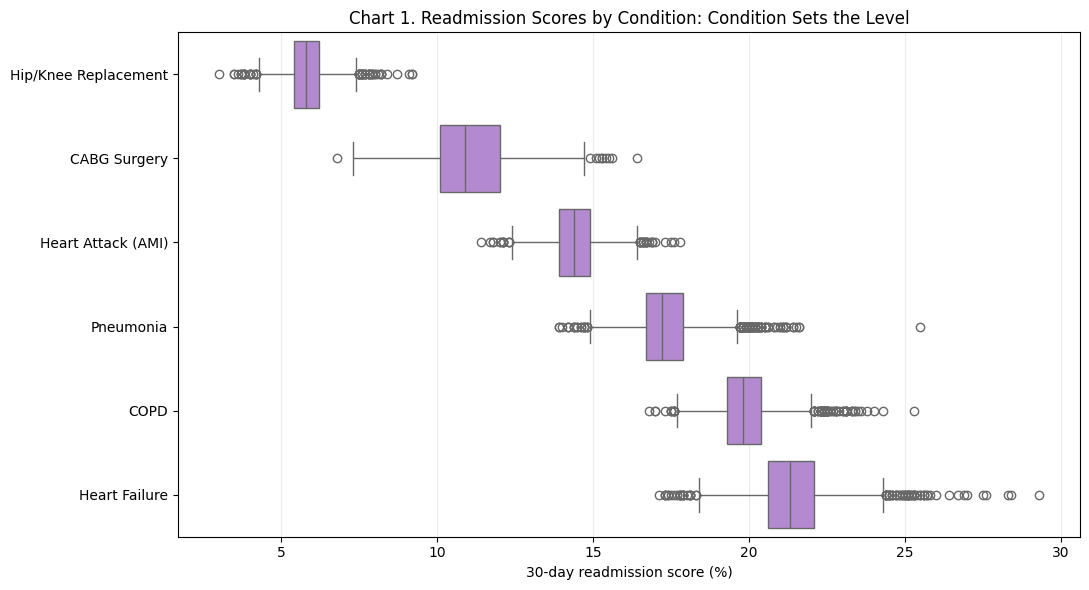

,Median,IQR
Measure Label,,
Hip/Knee Replacement,5.8,0.8
CABG Surgery,10.9,1.9
Heart Attack (AMI),14.4,1.0
Pneumonia,17.2,1.2
COPD,19.8,1.1
Heart Failure,21.3,1.5


Across-condition range of medians: 15.5 pp
Typical within-condition IQR: 1.1 pp
Ratio: 13.5x -> H1 supported (rule: 3x or more)
Bootstrap 95% CI for the ratio: [12.9x, 13.6x] -> the whole interval is at least 3x, so H0 is also rejected under resampling


In [ ]:
# H1: Condition, not hospital, drives raw scores. (Chart 1)

by_condition = hospital_valid.groupby("Measure Label")["Score"]
condition_medians = by_condition.median()
condition_iqr = by_condition.quantile(0.75) - by_condition.quantile(0.25)
across_range = condition_medians.max() - condition_medians.min()
typical_within_iqr = condition_iqr.median()
h1_ratio = across_range / typical_within_iqr
order = condition_medians.sort_values().index

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=hospital_valid, x="Score", y="Measure Label", order=order, color=LIGHT_PURPLE, ax=ax)
ax.set_xlabel("30-day readmission score (%)")
ax.set_ylabel("")
ax.set_title("Chart 1. Readmission Scores by Condition: Condition Sets the Level")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()
display(pd.DataFrame({"Median": condition_medians, "IQR": condition_iqr}).loc[order].round(2))

print(f"Across-condition range of medians: {across_range:.1f} pp")
print(f"Typical within-condition IQR: {typical_within_iqr:.1f} pp")
print(f"Ratio: {h1_ratio:.1f}x -> H1 {'supported' if h1_ratio >= 3 else 'not supported'} (rule: 3x or more)")

# Robustness: bootstrap the ratio (resample hospitals within each condition, 1,000 times)
rng = np.random.default_rng(42)
cond_scores = {m: g.to_numpy() for m, g in hospital_valid.groupby("Measure Label")["Score"]}
boot_ratio = []
for _ in range(1000):
    meds, iqrs = [], []
    for v in cond_scores.values():
        resample = rng.choice(v, size=len(v), replace=True)
        low_q, high_q = np.percentile(resample, [25, 75])
        meds.append(np.median(resample))
        iqrs.append(high_q - low_q)
    boot_ratio.append((max(meds) - min(meds)) / np.median(iqrs))

h1_lo, h1_hi = np.percentile(boot_ratio, [2.5, 97.5])
print(f"Bootstrap 95% CI for the ratio: [{h1_lo:.1f}x, {h1_hi:.1f}x] -> "
+ ("the whole interval is at least 3x, so H0 is also rejected under resampling" if h1_lo >= 3
else "the interval crosses 3x, so report H1 with this caveat"))
results.append({"Hypothesis": "H1", "Role": "Descriptive", "Test": "Median range / median IQR",
"n": len(hospital_valid), "Statistic": f"ratio = {h1_ratio:.1f}x", "Effect size": "",
"Raw p": np.nan, "Verdict": "Supported" if h1_ratio >= 3 else "Not supported"})

**Verdict on H1: Supported, so we reject H0** (ratio = 13.5x; the condition medians span 15.5 pp, from 5.8% for hip/knee replacement to 21.3% for heart failure, while the typical within-condition IQR is only 1.1 pp).

**So what:** A state's raw average score would mostly reflect which conditions its hospitals treat. Every later test therefore compares each hospital with the national median **for the same condition** (the "gap"), not the raw score.

**Robustness:** The code under Chart 1 resamples hospitals within each condition 1,000 times and prints whether the whole 95% interval for the ratio stays at or above 3x.

### H2. State gaps
**Question of Interest:** Do states differ only slightly from the national readmission rate for the same condition?

**Alternative (Ha):** The range of state median readmission gaps (score minus the national median for the same condition) is under 1.5 percentage points.

**Null (H0):** The range is 1.5 pp or more, so states differ meaningfully from the national rate.

**Test and Decision Rule:** Highest minus lowest state median gap across the 52 geographies; reject H0 if the range is under 1.5 pp.


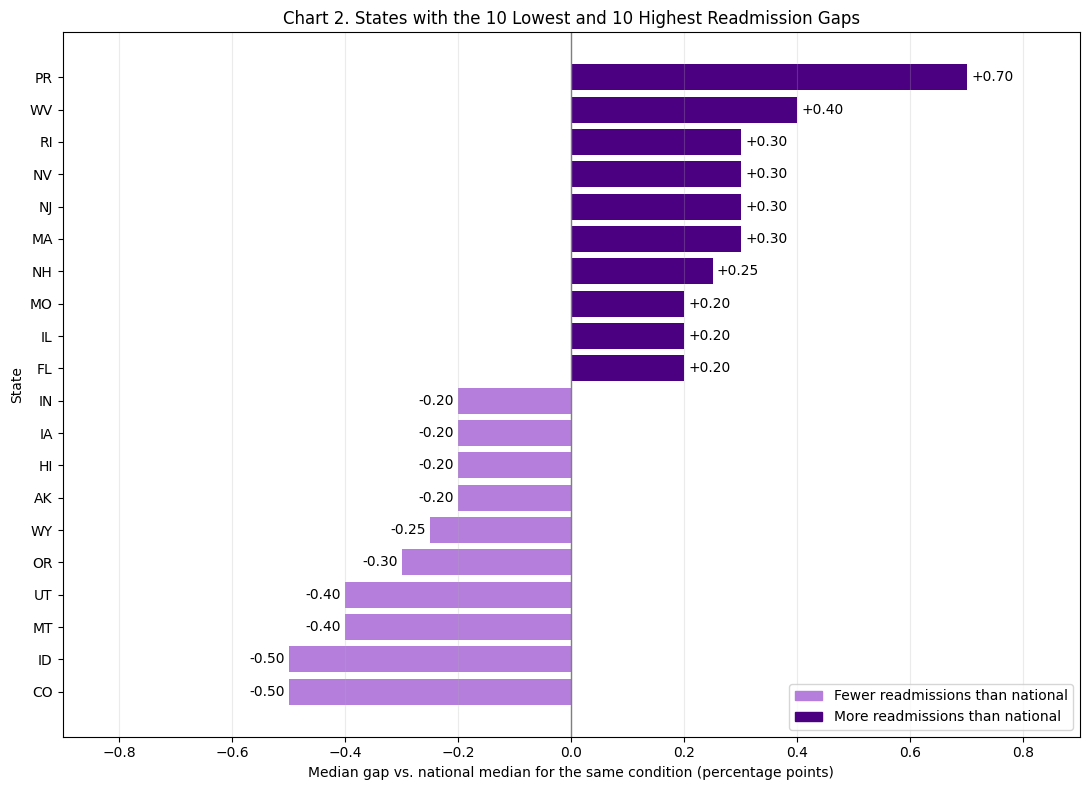

States: 52 | lowest -0.50 ['CO', 'ID'] | highest +0.70 ['PR']
Highest five: [['NJ', 0.3], ['NV', 0.3], ['RI', 0.3], ['WV', 0.4], ['PR', 0.7]]
Range: 1.20 pp -> H2 supported (rule: under 1.5 pp)
States with fewer than 10 hospitals: ['DC', 'DE']


In [ ]:
#H2: state readmission gaps are narrow - Chart 2

# Compare each score with the national median of the SAME condition (groupby + transform)
hospital_valid["National_Median"] = hospital_valid.groupby("Measure ID")["Score"].transform("median")
hospital_valid["Gap_vs_National"] = hospital_valid["Score"] - hospital_valid["National_Median"]

# The 52 geographies covered by both sources (drops GU, MP, VI)
q3 = hospital_valid[hospital_valid["State_Name"].notnull()].copy()
state_gap = q3.groupby(["State", "State_Name"]).agg({"Gap_vs_National": "median", "Facility ID":
"nunique"})
state_gap.columns = ["Median_Gap", "Hospitals"]
state_gap["Median_Gap"] = state_gap["Median_Gap"].round(2)
state_gap = state_gap.reset_index().sort_values(["Median_Gap", "State"])
chart_data = pd.concat([state_gap.head(10), state_gap.tail(10)])

fig, ax = plt.subplots(figsize=(11, 8))
colors = np.where(chart_data["Median_Gap"] < 0, LIGHT_PURPLE, DARK_PURPLE)
bars = ax.barh(chart_data["State"], chart_data["Median_Gap"], color=colors)
ax.bar_label(bars, fmt="%+.2f", padding=3)
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_xlim(-0.9, 0.9)
ax.set_xlabel("Median gap vs. national median for the same condition (percentage points)")
ax.set_ylabel("State")
ax.set_title("Chart 2. States with the 10 Lowest and 10 Highest Readmission Gaps")
ax.grid(axis="x", alpha=0.25)

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=LIGHT_PURPLE, label="Fewer readmissions than national"),
Patch(color=DARK_PURPLE, label="More readmissions than national")], loc="lower right")
plt.tight_layout()
plt.show()

h2_range = state_gap["Median_Gap"].max() - state_gap["Median_Gap"].min()

print(f"States: {len(state_gap)} | lowest {state_gap['Median_Gap'].min():+.2f} "
f"{list(state_gap.loc[state_gap['Median_Gap'] == state_gap['Median_Gap'].min(), 'State'])} | "
f"highest {state_gap['Median_Gap'].max():+.2f} {list(state_gap.loc[state_gap['Median_Gap'] ==
state_gap['Median_Gap'].max(), 'State'])}")
print("Highest five:", state_gap.tail(5)[["State", "Median_Gap"]].values.tolist())
print(f"Range: {h2_range:.2f} pp -> H2 {'supported' if h2_range < 1.5 else 'not supported'} (rule: under 1.5 pp)")
print("States with fewer than 10 hospitals:", list(state_gap.loc[state_gap["Hospitals"] < 10, "State"]))
results.append({"Hypothesis": "H2", "Role": "Descriptive", "Test": "Range of state median gaps",
"n": len(state_gap), "Statistic": f"range = {h2_range:.2f} pp", "Effect size": "",
"Raw p": np.nan, "Verdict": "Supported" if h2_range < 1.5 else "Not supported"})

**Verdict on H2:** Supported, so we reject H0 (range = 1.20 pp, from −0.50 in Colorado and Idaho to +0.70 in Puerto Rico; the rule was under 1.5 pp).

**So what:** Even the "worst" state is less than one percentage point above the national rate for the same condition, so any coverage effect has very little room to show up. DC and Delaware have fewer than 10 reporting hospitals, so their gaps are less stable.

**Note:** The 52 geographies are the whole population we study, not a sample of states, so the range is reported as observed and needs no interval. The small-state caveat is in Limitation 6.

### H3. Coverage spread
**Question of Interest:** Do state uninsured rates differ widely?

**Alternative (Ha):** The highest state uninsured rate (2023-2024 average) is at least 3 times the lowest.

**Null (H0):** The highest is less than 3 times the lowest, so coverage is similar across states.

**Test and Decision rule:** Highest divided by lowest state uninsured rate; reject H0 if the ratio is 3 or more.

**Robustness:** The ratio is recomputed for each year (2022, 2023, 2024) to show it does not depend on the averaging.

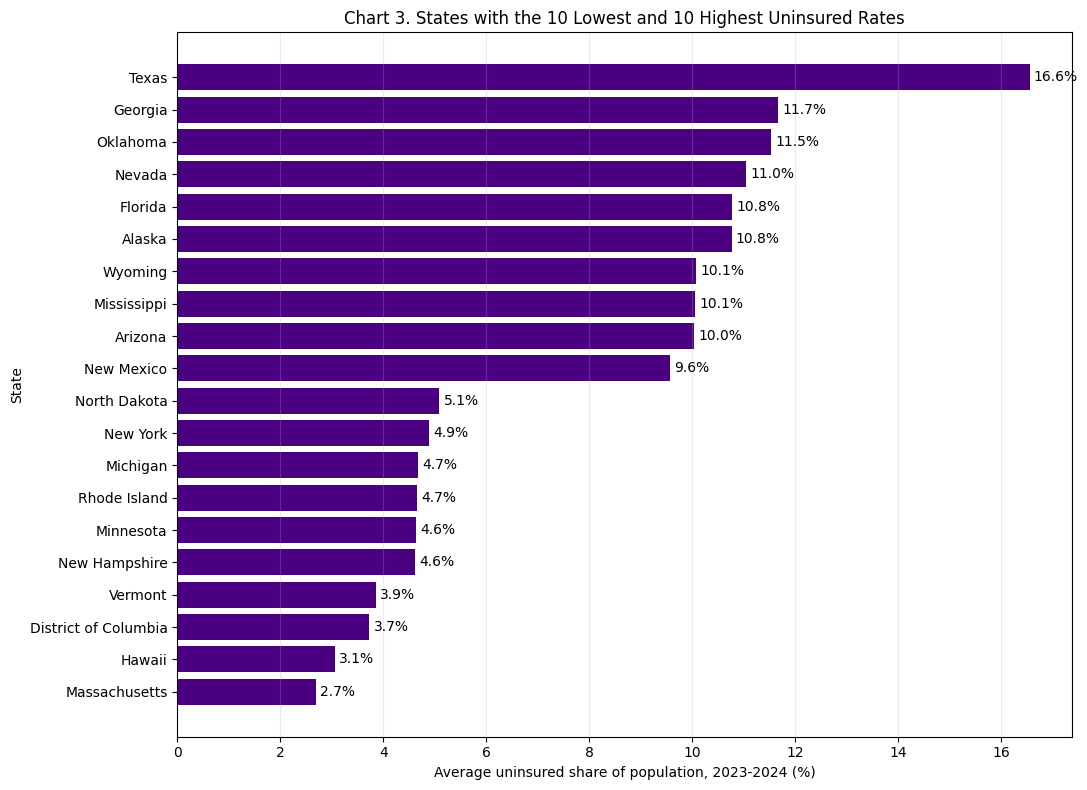

Lowest: Massachusetts 2.69% | Highest: Texas 16.56%
Ratio: 6.2x -> H3 supported (rule: 3x or more)
Ratio of highest to lowest uninsured rate by year: {2022: 6.9, 2023: 6.2, 2024: 6.1} -> at least 3x in every year: True


In [ ]:
# H3: state uninsured rates differ widely -Chart 3

# One row per state, one column per year (pivot_table)
uninsured_by_year = insurance.pivot_table(values="Uninsured_%", index="State", columns="Year")
uninsured_by_year["Avg_2023_2024"] = uninsured_by_year[[2023, 2024]].mean(axis="columns")

# Same shape as the draft code expects: State (full name), Average_Uninsured
state_insurance = uninsured_by_year["Avg_2023_2024"].rename("Average_Uninsured").reset_index()
ranked = state_insurance.sort_values("Average_Uninsured")
chart_data = pd.concat([ranked.head(10), ranked.tail(10)])

fig, ax = plt.subplots(figsize=(11, 8))
bars = ax.barh(chart_data["State"], chart_data["Average_Uninsured"], color=DARK_PURPLE)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Average uninsured share of population, 2023-2024 (%)")
ax.set_ylabel("State")
ax.set_title("Chart 3. States with the 10 Lowest and 10 Highest Uninsured Rates")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

lowest, highest = ranked.iloc[0], ranked.iloc[-1]
h3_ratio = highest["Average_Uninsured"] / lowest["Average_Uninsured"]
print(f"Lowest: {lowest['State']} {lowest['Average_Uninsured']:.2f}% | Highest: {highest['State']} {highest['Average_Uninsured']:.2f}%")
print(f"Ratio: {h3_ratio:.1f}x -> H3 {'supported' if h3_ratio >= 3 else 'not supported'} (rule: 3x or more)")

# Robustness: does the ratio hold in each year separately?
ratio_by_year = {y: uninsured_by_year[y].max() / uninsured_by_year[y].min() for y in [2022, 2023, 2024]}
print("Ratio of highest to lowest uninsured rate by year:", {y: round(v, 1) for y, v in
ratio_by_year.items()},
"-> at least 3x in every year:", all(v >= 3 for v in ratio_by_year.values()))
results.append({"Hypothesis": "H3", "Role": "Descriptive", "Test": "Max / min uninsured rate",
"n": len(state_insurance), "Statistic": f"ratio = {h3_ratio:.1f}x", "Effect size": "",
"Raw p": np.nan, "Verdict": "Supported" if h3_ratio >= 3 else "Not supported"})

**Verdict on H3:** Supported, so we reject H0 (ratio = 6.2x; Texas 16.56% vs. Massachusetts 2.69%, 2023–2024 average).

**So what:** Coverage varies a lot across states while readmission gaps barely move (H2). That contrast is the first sign that coverage is unlikely to explain much of the readmission variation.

**Robustness:** The ratio is also computed for each year separately (printed under Chart 3).

### H4. Data coverage
**Question of Interest:** Is at least one condition reported by too few hospitals for a reliable comparison?

**Alternative (Ha):** At least one of the six conditions has fewer than 1,000 usable hospital records.

**Null (H0):** Every condition has 1,000 or more usable records.

**Test and Decision rule:** Count usable records per condition; reject H0 if the smallest count is under 1,000.

**Note:** H4 is a count of records, not a sample estimate, so it needs no interval.

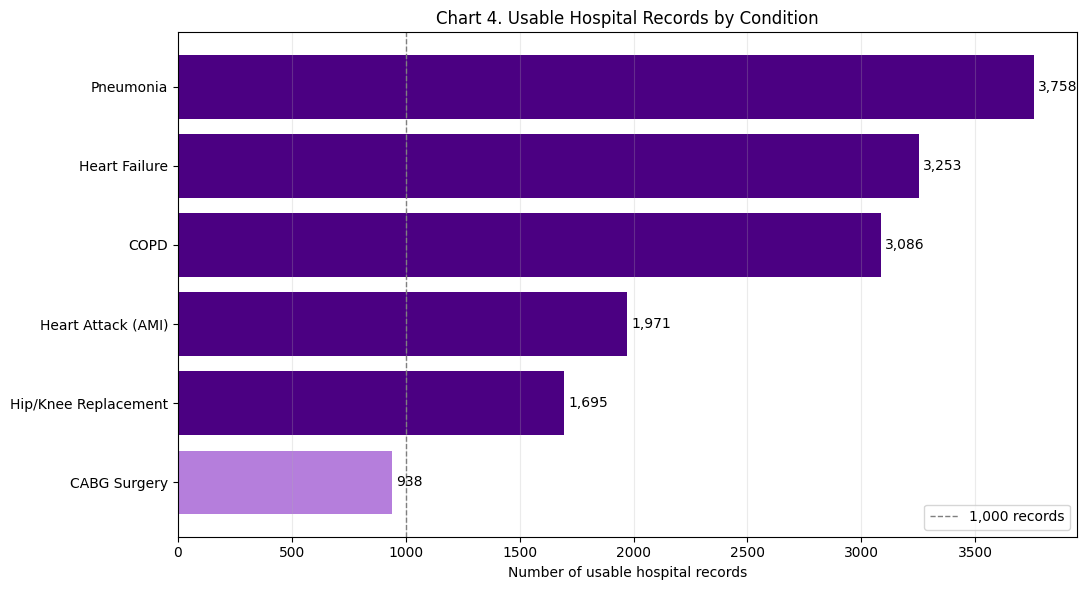

,Usable Records,States Reporting
Measure Label,,
CABG Surgery,938,52
Hip/Knee Replacement,1695,52
Heart Attack (AMI),1971,52
COPD,3086,52
Heart Failure,3253,52
Pneumonia,3758,52


Conditions under 1,000 records: 1 -> H4 supported


In [ ]:
#H4: usable records are uneven across conditions - Chart 4

measure_counts = hospital_valid.groupby("Measure Label").agg({"Score": "count", "State_Name": "nunique"})
measure_counts.columns = ["Usable Records", "States Reporting"]
measure_counts = measure_counts.sort_values("Usable Records")
fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(measure_counts.index, measure_counts["Usable Records"],
color=np.where(measure_counts["Usable Records"] < 1000, LIGHT_PURPLE, DARK_PURPLE))

ax.bar_label(bars, fmt="{:,.0f}", padding=3)
ax.axvline(1000, color=GRAY, linestyle="--", linewidth=1, label="1,000 records")
ax.set_xlabel("Number of usable hospital records")
ax.set_ylabel("")
ax.set_title("Chart 4. Usable Hospital Records by Condition")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(measure_counts)
n_under = (measure_counts["Usable Records"] < 1000).sum()
print(f"Conditions under 1,000 records: {n_under} -> H4 {'supported' if n_under >= 1 else 'not supported'}")
results.append({"Hypothesis": "H4", "Role": "Descriptive", "Test": "Records per condition", "n": len(measure_counts),
"Statistic": f"min = {measure_counts['Usable Records'].min():,}, max = {measure_counts['Usable Records'].max():,}","Effect size": "", "Raw p": np.nan, "Verdict": "Supported" if n_under >= 1 else "Not supported"})

**Verdict on H4:** Supported, so we reject H0 (CABG surgery has 938 usable records, the only condition under 1,000; pneumonia has 3,758). All six conditions are still reported in all 52 geographies.

**So what:** Results for CABG, and therefore for the elective group in H8, rest on fewer hospitals and should be read with more caution.

**Section Takeaway (H1 to H4):** The data are usable, but the analysis must compare hospitals with the national median for the same condition. States differ little in readmissions (1.20 pp) while coverage differs a lot (6.2x). That contrast is why a coverage effect on readmissions is doubtful, which Sections 6 to 10 test directly.

## 6. Does Medicaid Expansion Lower the Uninsured Rate?

Before testing readmissions, we check the first link in the chain: if expansion helps coverage, expansion states should have lower uninsured rates than the states that did not expand.

### H5 (secondary). Expansion and uninsured rate

**Question of Interest:** Do Medicaid-expansion states have lower uninsured rates than non-expansion states?

**Alternative (Ha):** The mean uninsured rate (2023-2024 average) is lower in the 41 expansion states than in the 10 non-expansion states.

**Null (H0):** The expansion mean is equal or higher.

**Test and decision rule:** one-sided Welch t-test with Cohen's d, Puerto Rico excluded; reject H0 if Holm p < 0.05.

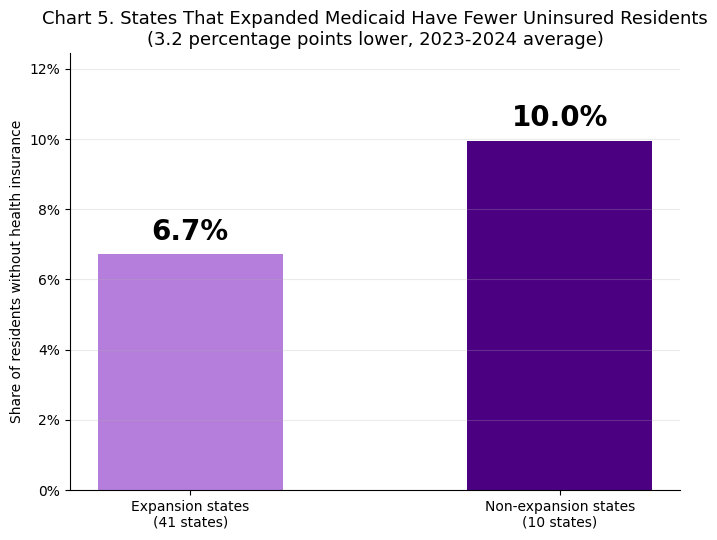

                  count  mean  median   std
Expansion_Status                           
Expansion            41  6.72    6.41  2.13
Non-Expansion        10  9.96    9.76  2.91

Difference (expansion - non-expansion): -3.24 pp, d = -1.41, t = -3.31, one-sided p = 0.003303


In [ ]:
# H5: Medicaid expansion goes with lower uninsured rates (Chart 5)

# Puerto Rico is outside the ACA expansion framework, so it is excluded from this test (as in H7, H9 and H12)
h5_df = state_insurance[state_insurance["State"] != "Puerto Rico"].copy()
h5_df["Expansion_Status"] = np.where(h5_df["State"].isin(non_expansion_states), "Non-Expansion", "Expansion")
exp5 = h5_df.loc[h5_df["Expansion_Status"] == "Expansion", "Average_Uninsured"]
non5 = h5_df.loc[h5_df["Expansion_Status"] == "Non-Expansion", "Average_Uninsured"]

# Welch t-test (one-sided: we predict LOWER uninsured rates in expansion states) and Cohen's d)
t5, p5_two = stats.ttest_ind(exp5, non5, equal_var=False)
p5 = one_sided(p5_two, t5, expect_positive=False)
d5 = cohens_d(exp5, non5)

# Chart 5: one bar per group, the number on each bar
fig, ax = plt.subplots(figsize=(7, 5.5))
bars = ax.bar(["Expansion states\n(41 states)", "Non-expansion states\n(10 states)"], [exp5.mean(), non5.mean()],
              color=[LIGHT_PURPLE, DARK_PURPLE], width=0.5)
ax.bar_label(bars, labels=[f"{exp5.mean():.1f}%", f"{non5.mean():.1f}%"], fontsize=20, fontweight="bold", padding=6)
ax.set_ylim(0, non5.mean() * 1.25)
ax.set_ylabel("Share of residents without health insurance")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_title(f"Chart 5. States That Expanded Medicaid Have Fewer Uninsured Residents\n"
             f"({non5.mean() - exp5.mean():.1f} percentage points lower, 2023-2024 average)", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

print(h5_df.groupby("Expansion_Status")["Average_Uninsured"].agg(["count", "mean", "median", "std"]).round(2))
print(f"\nDifference (expansion - non-expansion): {exp5.mean() - non5.mean():+.2f} pp, d = {d5:+.2f}, "
      f"t = {t5:.2f}, one-sided p = {p5:.6f}")
results.append({"Hypothesis": "H5", "Role": "Secondary", "Test": "Welch t-test, one-sided",
                "n": f"{len(exp5)} vs {len(non5)}", "Statistic": f"t = {t5:.2f}",
                "Effect size": f"{exp5.mean() - non5.mean():+.2f} pp, d = {d5:+.2f}", "Raw p": p5, "Verdict": None})

**Verdict on H5:** Supported, so we reject H0 (expansion states average 6.72% uninsured against 9.96% in non-expansion states; difference −3.24 pp, Cohen's d = −1.41, Welch t = −3.31, one-sided p = 0.0033, Holm p = 0.0066; n = 41 vs 10).

**So what:** Expansion goes with much lower uninsured rates, a large effect. That makes the readmission results more informative: expansion states have far fewer uninsured residents, yet (H7) their readmission gaps look the same as in non-expansion states. Seven of the ten non-expansion states are in the South, so region and income may also play a part. This is an association, not proof that expansion caused the lower rate.

## 7. Core Test: Does Coverage Go With Readmissions?

### H6 (primary). Uninsured Rate and Readmission gap
**Question of Interest:** Do states with a higher uninsured rate have a higher readmission gap?

**Alternative (Ha):** Across states, the uninsured rate is positively correlated with the median readmission gap (r > 0).

**Null (H0):** r is zero or negative.

**Test and Decision Rule:** One-sided Pearson correlation at alpha = 0.05 across 52 geographies (Spearman as a check), repeated without Puerto Rico; reject H0 only if p < 0.05 in both.

States in the analysis: 52


,n,Pearson r,95% CI,R-squared,one-sided p,Spearman rho,Spearman one-sided p
Sample,,,,,,,
All 52,52,-0.112,"[-0.37, +0.17]",0.012,0.784,-0.104,0.769
Without PR,51,-0.076,"[-0.34, +0.20]",0.006,0.702,-0.081,0.715


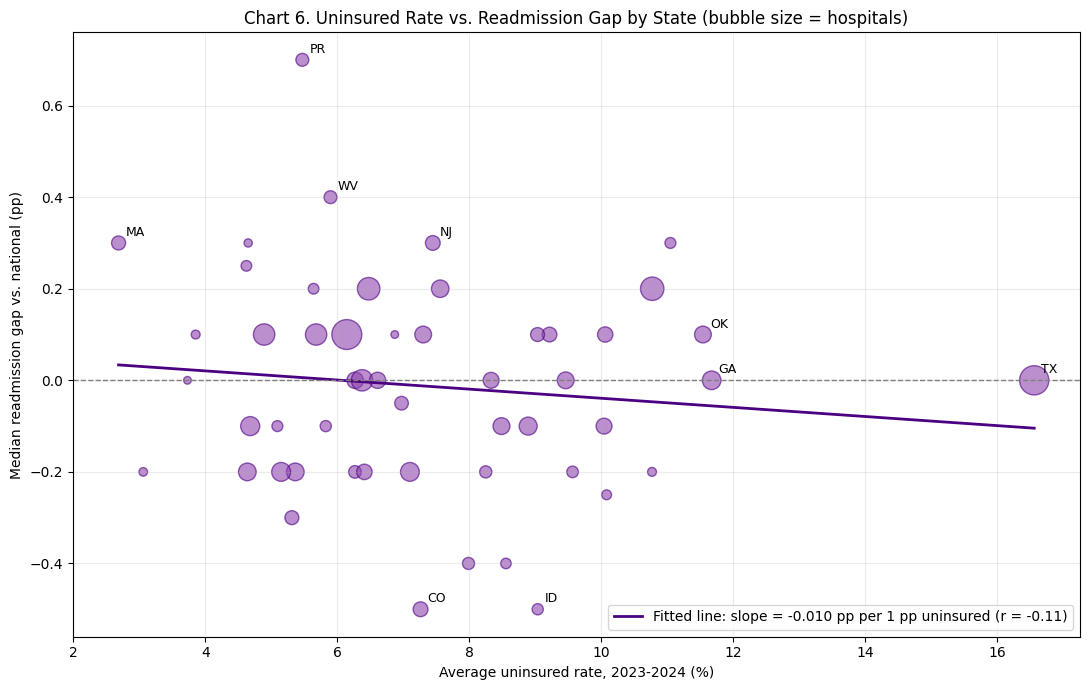

Least and best insured states:


,State,Average_Uninsured,Median_Gap
29,TX,16.56,0.0
46,MA,2.69,0.3


H6 verdict: Not supported


In [ ]:
# H6 (primary): higher uninsured rate, higher readmission gap

# One row per state: readmission gap + uninsured rate
h6_df = pd.merge(state_gap, state_insurance, left_on="State_Name", right_on="State",
how="inner", suffixes=("", "_kff")).drop(columns="State_kff")
print("States in the analysis:", len(h6_df))
rows = []
for label, d in [("All 52", h6_df), ("Without PR", h6_df[h6_df["State"] != "PR"])]:
    r, p = stats.pearsonr(d["Average_Uninsured"], d["Median_Gap"])
    rho, p_s = stats.spearmanr(d["Average_Uninsured"], d["Median_Gap"])
    lo, hi = r_ci(r, len(d))
    rows.append({"Sample": label, "n": len(d), "Pearson r": r, "95% CI": f"[{lo:+.2f}, {hi:+.2f}]",
        "R-squared": r ** 2, "one-sided p": one_sided(p, r),
        "Spearman rho": rho, "Spearman one-sided p": one_sided(p_s, rho)})
h6_table = pd.DataFrame(rows).set_index("Sample")
display(h6_table.round(3))
r6, p6 = h6_table.loc["All 52", "Pearson r"], h6_table.loc["All 52", "one-sided p"]
p6_noPR = h6_table.loc["Without PR", "one-sided p"]

# Chart 6: bubble size = number of hospitals, with a fitted line
x, y = h6_df["Average_Uninsured"], h6_df["Median_Gap"]
slope, intercept = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 100)
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(x, y, s=h6_df["Hospitals"] * 1.5 + 20, color=MEDIUM_PURPLE, alpha=0.6, edgecolor=DARK_PURPLE)
ax.plot(xs, slope * xs + intercept, color=DARK_PURPLE, linewidth=2,
label=f"Fitted line: slope = {slope:+.3f} pp per 1 pp uninsured (r = {r6:+.2f})")

for _, row in h6_df.iterrows():
    if row["State"] in ["PR", "TX", "MA", "CO", "ID", "NJ", "WV", "GA", "OK"]:
        ax.annotate(row["State"], (row["Average_Uninsured"], row["Median_Gap"]),
            xytext=(5, 5), textcoords="offset points", fontsize=9)

ax.axhline(0, color=GRAY, linewidth=1, linestyle="--")
ax.set_xlabel("Average uninsured rate, 2023-2024 (%)")
ax.set_ylabel("Median readmission gap vs. national (pp)")
ax.set_title("Chart 6. Uninsured Rate vs. Readmission Gap by State (bubble size = hospitals)")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Least and best insured states:")
display(h6_df[h6_df["State"].isin(["TX", "MA"])][["State", "Average_Uninsured", "Median_Gap"]].round(2))
verdict6 = "Supported" if (p6 < 0.05 and p6_noPR < 0.05) else "Not supported"
print(f"H6 verdict: {verdict6}")
results.append({"Hypothesis": "H6", "Role": "Primary", "Test": "Pearson r, one-sided (Spearman check)",
"n": len(h6_df), "Statistic": f"r = {r6:+.2f} (without PR {h6_table.loc['Without PR',
'Pearson r']:+.2f})",
"Effect size": f"R-squared = {r6 ** 2:.2f}", "Raw p": p6, "Verdict": verdict6})

**Verdict on H6:** **Not supported, so we fail to reject H0** (Pearson r = −0.11, 95% CI [−0.37, +0.17], R² = 0.01, one-sided
p = 0.78; without Puerto Rico r = −0.08, p = 0.70; Spearman ρ = −0.10). The fitted line is flat and slightly in the opposite direction from the prediction. Texas, the least-insured state, sits close to zero, and Massachusetts, the best-insured state, is above zero.

**So what:** Across states, more uninsured residents do not go with more readmissions. This does not show that insurance is irrelevant to an individual patient. It shows that a state's overall uninsured rate is not a useful signal for where readmission money should go.

### H6b (Robustness). The same link using CMS classification

**Question of Interest:** Does the H6 result hold when readmission performance is measured by CMS's own "worse than national" classification?

**Alternative (Ha):** The uninsured rate is positively correlated with the share of a state's hospitals that CMS rates worse than the national rate.

**Null (H0):** The correlation is zero or negative.

**Test and Decision Rule:** Pearson and Spearman correlations across states; the robustness check passes if the sign matches H6.

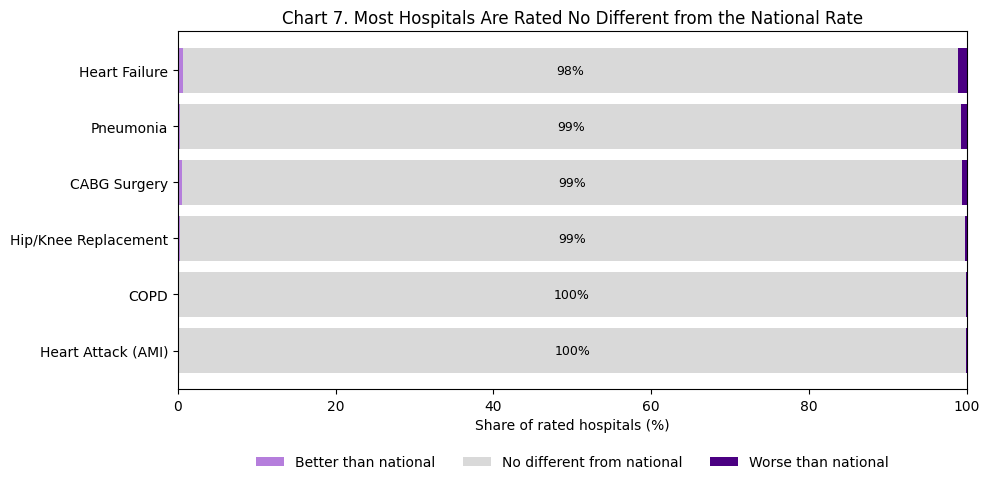

n = 52, Pearson r = -0.08 [-0.34, +0.20], one-sided p = 0.7034
Spearman rho = -0.00, one-sided p = 0.5077
Same sign as H6: True


In [ ]:
# H6b: robustness using CMS's own classification (Chart 7 shows the CMS ratings behind it)

# CMS's own classification: share of hospitals rated "worse than national", readmission measures only
state_readm = state[state["Measure ID"].str.startswith("READM_30_", na=False)].copy()
state_readm["Total_Classified"] = state_readm[["Number of Hospitals Worse", "Number of Hospitals Same",
"Number of Hospitals Better"]].sum(axis=1)
state_readm = state_readm[state_readm["Total_Classified"] > 0].copy()
state_readm["Pct_Worse"] = state_readm["Number of Hospitals Worse"] / state_readm["Total_Classified"] *100
state_worse = state_readm.groupby("State_Name")["Pct_Worse"].mean().reset_index()
h6b_df = pd.merge(state_worse, state_insurance, left_on="State_Name", right_on="State", how="inner")
r6b, p6b_two = stats.pearsonr(h6b_df["Average_Uninsured"], h6b_df["Pct_Worse"])
rho6b, p6b_s = stats.spearmanr(h6b_df["Average_Uninsured"], h6b_df["Pct_Worse"])
lo, hi = r_ci(r6b, len(h6b_df))

# Chart 7: how CMS itself rates hospitals on each condition (all states combined)
label_map = hospital_valid.drop_duplicates("Measure ID").set_index("Measure ID")["Measure Label"]
cms_counts = state_readm.groupby("Measure ID")[["Number of Hospitals Better", "Number of Hospitals Same",
                                                "Number of Hospitals Worse"]].sum()
cms_pct = cms_counts.div(cms_counts.sum(axis=1), axis=0) * 100
cms_pct.index = cms_pct.index.map(label_map)
cms_pct = cms_pct.sort_values("Number of Hospitals Worse")
fig, ax = plt.subplots(figsize=(10, 5))
left = np.zeros(len(cms_pct))
for col, name, color in [("Number of Hospitals Better", "Better than national", LIGHT_PURPLE),
                         ("Number of Hospitals Same", "No different from national", "#D9D9D9"),
                         ("Number of Hospitals Worse", "Worse than national", DARK_PURPLE)]:
    ax.barh(cms_pct.index, cms_pct[col], left=left, color=color, label=name)
    for y, (l, w) in enumerate(zip(left, cms_pct[col])):
        if w >= 6:
            ax.text(l + w / 2, y, f"{w:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if color == DARK_PURPLE else "black")
    left += cms_pct[col].values

ax.set_xlabel("Share of rated hospitals (%)")
ax.set_xlim(0, 100)
ax.set_title("Chart 7. Most Hospitals Are Rated No Different from the National Rate")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

same_sign = np.sign(r6b) == np.sign(r6)
print(f"n = {len(h6b_df)}, Pearson r = {r6b:+.2f} [{lo:+.2f}, {hi:+.2f}], one-sided p = {one_sided(p6b_two, r6b):.4f}")
print(f"Spearman rho = {rho6b:+.2f}, one-sided p = {one_sided(p6b_s, rho6b):.4f}")
print(f"Same sign as H6: {same_sign}")
results.append({"Hypothesis": "H6b", "Role": "Robustness", "Test": "Pearson + Spearman",
"n": len(h6b_df), "Statistic": f"r = {r6b:+.2f}, rho = {rho6b:+.2f}",
"Effect size": f"R-squared = {r6b ** 2:.2f}", "Raw p": one_sided(p6b_two, r6b),
"Verdict": "Same sign as H6" if same_sign else "Opposite sign to H6"})

**Verdict on H6b:** Consistent with H6, so the robustness check passes. The correlation is also near zero (r = −0.08, 95% CI [−0.34, +0.20]; Spearman ρ = −0.00), with the same sign as H6.

**So what:** The null result in H6 is not caused by our custom gap metric. CMS's own classification of hospitals tells the same story, but it is a weak check on its own, because almost every hospital is rated "no different" (Chart 7).

**Reading Chart 7:** For every condition, most hospitals are rated "no different from the national rate" and only a small share are rated worse. That is why the state-level "worse than national" share is so close to zero for many states, and why it cannot detect a link on its own.

**Section Takeaway (H6, H6b):** More uninsured residents do not go with higher readmission gaps, by either of two independent measures. For the funding decision this means the state uninsured rate is not a signal for where readmission money should go.

## 8. Policy Test: Medicaid Expansion

### H7. Medicaid Expansion and Readmission gap

**Question of Interest**: Do Medicaid-expansion states have lower readmission gaps than non-expansion states?

**Alternative (Ha):** The mean state readmission gap is lower in the 41 expansion states than in the 10 non-expansion
states.

**Null (H0):** The expansion-state mean is equal to or higher than the non-expansion mean.

**Test and Decision Rule:** One-sided Welch t-test at alpha = 0.05 with Cohen's d; Puerto Rico excluded; reject H0 if p < 0.05.

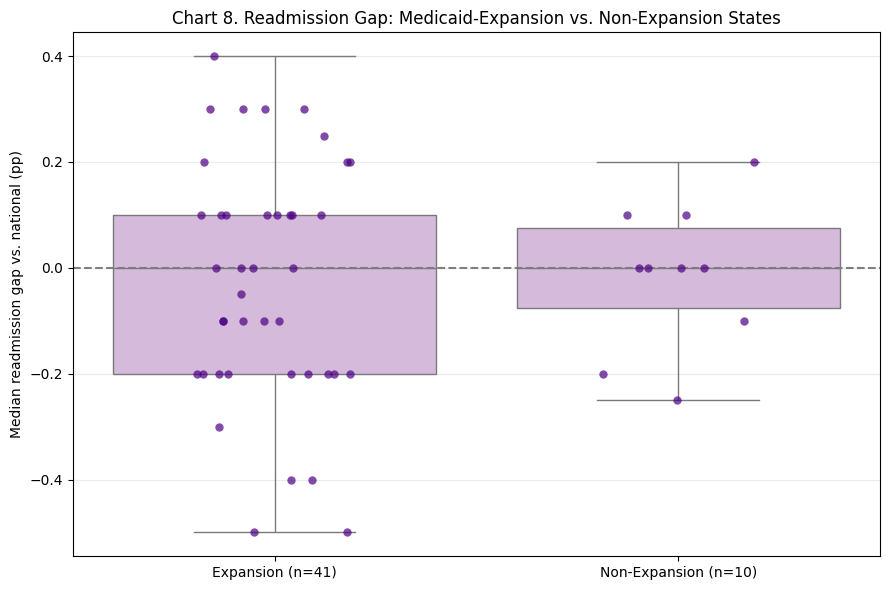

                  count  mean  median   std
Expansion_Status                           
Expansion            41 -0.03     0.0  0.23
Non-Expansion        10 -0.02     0.0  0.14

Difference (expansion - non-expansion): -0.01 pp, d = -0.07, t = -0.25, one-sided p = 0.4009
Non-expansion states: ['AL', 'FL', 'GA', 'KS', 'MS', 'SC', 'TN', 'TX', 'WI', 'WY']
Without NC and SD: difference -0.01 pp, d = -0.04, one-sided p = 0.4444


In [ ]:
# Puerto Rico is outside the ACA expansion framework, so it is excluded here
h7_df = h6_df[h6_df["State"] != "PR"].copy()
h7_df["Expansion_Status"] = np.where(
    h7_df["State_Name"].isin(non_expansion_states),
    "Non-Expansion",
    "Expansion"
)

exp = h7_df.loc[
    h7_df["Expansion_Status"] == "Expansion", "Median_Gap"
]
non = h7_df.loc[
    h7_df["Expansion_Status"] == "Non-Expansion", "Median_Gap"
]

t7, p7_two = stats.ttest_ind(exp, non, equal_var=False)
p7 = one_sided(p7_two, t7, expect_positive=False)
d7 = cohens_d(exp, non)

fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=h7_df,
    x="Expansion_Status",
    y="Median_Gap",
    order=["Expansion", "Non-Expansion"],
    color=PALE_PURPLE,
    showfliers=False,
    ax=ax
)

sns.stripplot(
    data=h7_df,
    x="Expansion_Status",
    y="Median_Gap",
    order=["Expansion", "Non-Expansion"],
    color=DARK_PURPLE,
    size=6,
    alpha=0.7,
    jitter=0.2,
    ax=ax
)

ax.axhline(0, color=GRAY, linestyle="--")
ax.set_xticks(
    [0, 1],
    [f"Expansion (n={len(exp)})",
     f"Non-Expansion (n={len(non)})"]
)
ax.set_xlabel("")
ax.set_ylabel("Median readmission gap vs. national (pp)")
ax.set_title(
    "Chart 8. Readmission Gap: Medicaid-Expansion vs. Non-Expansion States"
)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

print(
    h7_df.groupby("Expansion_Status")["Median_Gap"]
    .agg(["count", "mean", "median", "std"]).round(2)
)

print(
    f"\nDifference (expansion - non-expansion): "
    f"{exp.mean() - non.mean():+.2f} pp, d = {d7:+.2f}, "
    f"t = {t7:.2f}, one-sided p = {p7:.4f}"
)

print(
    "Non-expansion states:",
    sorted(
        h7_df.loc[
            h7_df["Expansion_Status"] == "Non-Expansion", "State"
        ]
    )
)

# Sensitivity: NC (Dec 2023) and SD (Jul 2023) expanded
# inside the CMS window; drop them and re-test
late = h7_df[~h7_df["State"].isin(["NC", "SD"])]

exp_s = late.loc[
    late["Expansion_Status"] == "Expansion", "Median_Gap"
]

t7s, p7s_two = stats.ttest_ind(
    exp_s, non, equal_var=False
)

print(
    f"Without NC and SD: difference "
    f"{exp_s.mean() - non.mean():+.2f} pp, "
    f"d = {cohens_d(exp_s, non):+.2f}, "
    f"one-sided p = "
    f"{one_sided(p7s_two, t7s, expect_positive=False):.4f}"
)

verdict7 = "Supported" if p7 < 0.05 else "Not supported"

results.append({
    "Hypothesis": "H7",
    "Role": "Primary",
    "Test": "Welch t-test, one-sided",
    "n": f"{len(exp)} vs {len(non)}",
    "Statistic": f"t = {t7:.2f}",
    "Effect size": (
        f"{exp.mean() - non.mean():+.2f} pp, d = {d7:+.2f}"
    ),
    "Raw p": p7,
    "Verdict": verdict7
})

**Verdict on H7:** Not supported, so we fail to reject H0 (difference −0.01 pp, Cohen's d = −0.07, Welch t = −0.25, one-sided p = 0.40; n = 41 vs 10). Both groups have a median gap of 0.00. Excluding North Carolina and South Dakota, which expanded during the CMS reporting window, does not change the result (difference −0.01 pp, p = 0.44).

**So what** : States that expanded Medicaid do not have measurably lower readmissions than the ten that did not. On readmission grounds alone, the data give a state no reason to expect expansion to reduce its CMS readmission penalties.

## 9. Where Does the Link Hold?

If the overall link is absent, it could still hide in a sub-group. H8 splits by type of condition and H9 by policy group.

### H8. Chronic versus elective conditions
**Question of Interest:** Is the insurance link stronger for chronic conditions than for elective procedures?

**Alternative (Ha):** The correlation between the uninsured rate and the readmission gap is stronger (more positive) for chronic conditions (AMI, heart failure, COPD) than for elective procedures (CABG, hip/knee).

**Null (H0):** The two correlations do not differ.

**Test and Decision Rule:** Two Pearson correlations with 95% confidence intervals; reject H0 if the intervals do not overlap and the chronic group is higher.

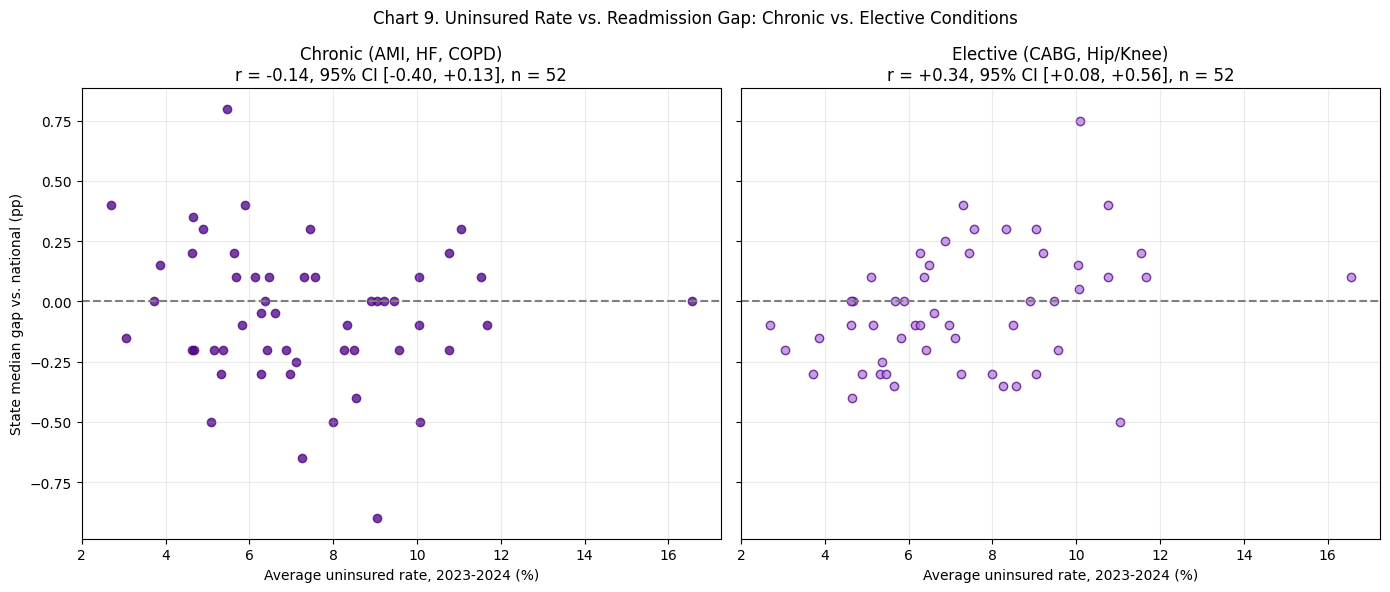

Chronic: r = -0.14 [-0.40, +0.13] | Elective: r = +0.34 [+0.08, +0.56]
CIs overlap: True


In [ ]:
chronic_measures  = ["READM_30_AMI", "READM_30_HF", "READM_30_COPD"]
elective_measures = ["READM_30_CABG", "READM_30_HIP_KNEE"]


def gap_by_group(measure_list):
    """State median gap for a subset of conditions, joined to the uninsured rate."""
    g = (q3[q3["Measure ID"].isin(measure_list)]
         .groupby("State_Name")["Gap_vs_National"]
         .median()
         .reset_index())
    return pd.merge(g, state_insurance,
                    left_on="State_Name", right_on="State", how="inner")


chronic_gap_df  = gap_by_group(chronic_measures)
elective_gap_df = gap_by_group(elective_measures)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
h8 = {}

for ax, (label, d, color) in zip(axes, [
    ("Chronic (AMI, HF, COPD)",   chronic_gap_df,  DARK_PURPLE),
    ("Elective (CABG, Hip/Knee)", elective_gap_df, LIGHT_PURPLE),
]):
    r, p = stats.pearsonr(d["Average_Uninsured"], d["Gap_vs_National"])
    lo, hi = r_ci(r, len(d))
    h8[label] = (r, lo, hi, len(d))

    ax.scatter(d["Average_Uninsured"], d["Gap_vs_National"],
               color=color, alpha=0.75, edgecolor=DARK_PURPLE)
    ax.axhline(0, color=GRAY, linestyle="--")
    ax.set_title(f"{label}\nr = {r:+.2f}, 95% CI [{lo:+.2f}, {hi:+.2f}], n = {len(d)}")
    ax.set_xlabel("Average uninsured rate, 2023-2024 (%)")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("State median gap vs. national (pp)")
fig.suptitle("Chart 9. Uninsured Rate vs. Readmission Gap: Chronic vs. Elective Conditions")
plt.tight_layout()
plt.show()

(rc, loc, hic, nc), (re, loe, hie, ne) = h8.values()
overlap = not (hic < loe or hie < loc)

print(f"Chronic: r = {rc:+.2f} [{loc:+.2f}, {hic:+.2f}] | "
      f"Elective: r = {re:+.2f} [{loe:+.2f}, {hie:+.2f}]")
print("CIs overlap:", overlap)

results.append({
    "Hypothesis": "H8",
    "Role": "Secondary",
    "Test": "Two Pearson r with 95% CIs",
    "n": f"{nc} / {ne}",
    "Statistic": f"r = {rc:+.2f} vs {re:+.2f}",
    "Effect size": f"CIs [{loc:+.2f}, {hic:+.2f}] vs [{loe:+.2f}, {hie:+.2f}]",
    "Raw p": np.nan,
    "Verdict": "No evidence of a difference" if overlap else "Supported",
})

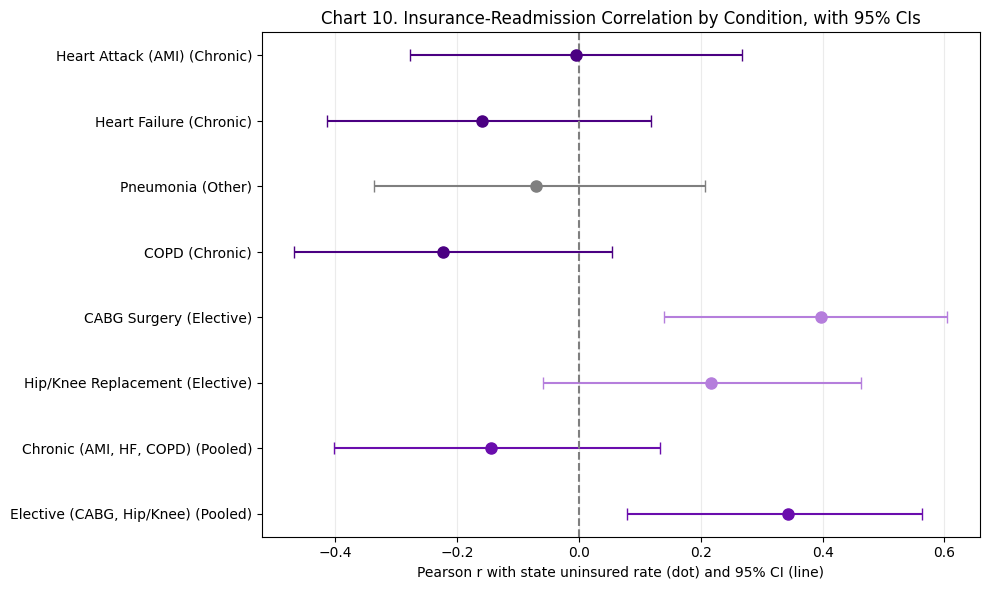

,Condition,Group,r,low,high,n
0,Heart Attack (AMI),Chronic,-0.00,-0.28,0.27,52
1,Heart Failure,Chronic,-0.16,-0.41,0.12,52
2,Pneumonia,Other,-0.07,-0.34,0.21,52
3,COPD,Chronic,-0.22,-0.47,0.05,52
4,CABG Surgery,Elective,0.40,0.14,0.60,52
5,Hip/Knee Replacement,Elective,0.22,-0.06,0.46,52
6,"Chronic (AMI, HF, COPD)",Pooled,-0.14,-0.40,0.13,52
7,"Elective (CABG, Hip/Knee)",Pooled,0.34,0.08,0.56,52


In [ ]:
# Chart 10: the same correlation for every condition, with its 95% CI
rows = []

for measure_id, label in measure_names.items():
    d = gap_by_group([measure_id])
    r, p = stats.pearsonr(d["Average_Uninsured"], d["Gap_vs_National"])
    lo, hi = r_ci(r, len(d))
    group = ("Chronic" if measure_id in chronic_measures
             else "Elective" if measure_id in elective_measures
             else "Other")
    rows.append({"Condition": label,
                 "Group": group,
                 "r": r,
                 "low": lo,
                 "high": hi,
                 "n": len(d)})

for label, (r, lo, hi, n) in h8.items():
    rows.append({"Condition": label,
                 "Group": "Pooled",
                 "r": r,
                 "low": lo,
                 "high": hi,
                 "n": n})

r_by_condition = pd.DataFrame(rows)

group_colors = {"Chronic":  DARK_PURPLE,
                "Elective": LIGHT_PURPLE,
                "Other":    GRAY,
                "Pooled":   PURPLE}

fig, ax = plt.subplots(figsize=(10, 6))

for i, row in r_by_condition.iterrows():
    ax.errorbar(row["r"], i,
                xerr=[[row["r"] - row["low"]], [row["high"] - row["r"]]],
                fmt="o", color=group_colors[row["Group"]],
                capsize=4, markersize=8)

ax.set_yticks(range(len(r_by_condition)),
              r_by_condition["Condition"] + " (" + r_by_condition["Group"] + ")")
ax.axvline(0, color=GRAY, linestyle="--")
ax.invert_yaxis()
ax.set_xlabel("Pearson r with state uninsured rate (dot) and 95% CI (line)")
ax.set_title("Chart 10. Insurance-Readmission Correlation by Condition, with 95% CIs")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

r_by_condition.round(2)

**Verdict on H8:** Not supported, so we fail to reject H0 (the difference points the opposite way from the prediction). The elective group, not the chronic group, shows the stronger link (chronic r = −0.14, 95% CI [−0.40,
+0.13]; elective r = +0.34, 95% CI [+0.08, +0.56]). Overlapping CIs is a conservative test, but the difference points the opposite way from the prediction, so the conclusion holds either way. By condition (Chart 10), CABG (r = +0.40, 95% CI [+0.14, +0.60]) is the only interval that excludes zero, but it is one of six uncorrected correlations on the smallest
sample (H4).

**So what:** The idea that insurance matters most for chronic conditions is not supported. Treat the CABG result as a lead for future work, not as a finding.

### H9. The Link Inside Each Policy Group
**Question of Interest:** Does the H6 link appear inside each policy group?

**Alternative (Ha):** Within expansion states, and separately within non-expansion states, the uninsured rate is positively correlated with the readmission gap.

**Null (H0):** Within a group, the correlation is zero or negative.

**Test and Decision Rule:** One-sided Pearson correlation per group; reject H0 for the expansion group if the Holm-adjusted p < 0.05 (the non-expansion group has only 10 states and is reported with its interval).

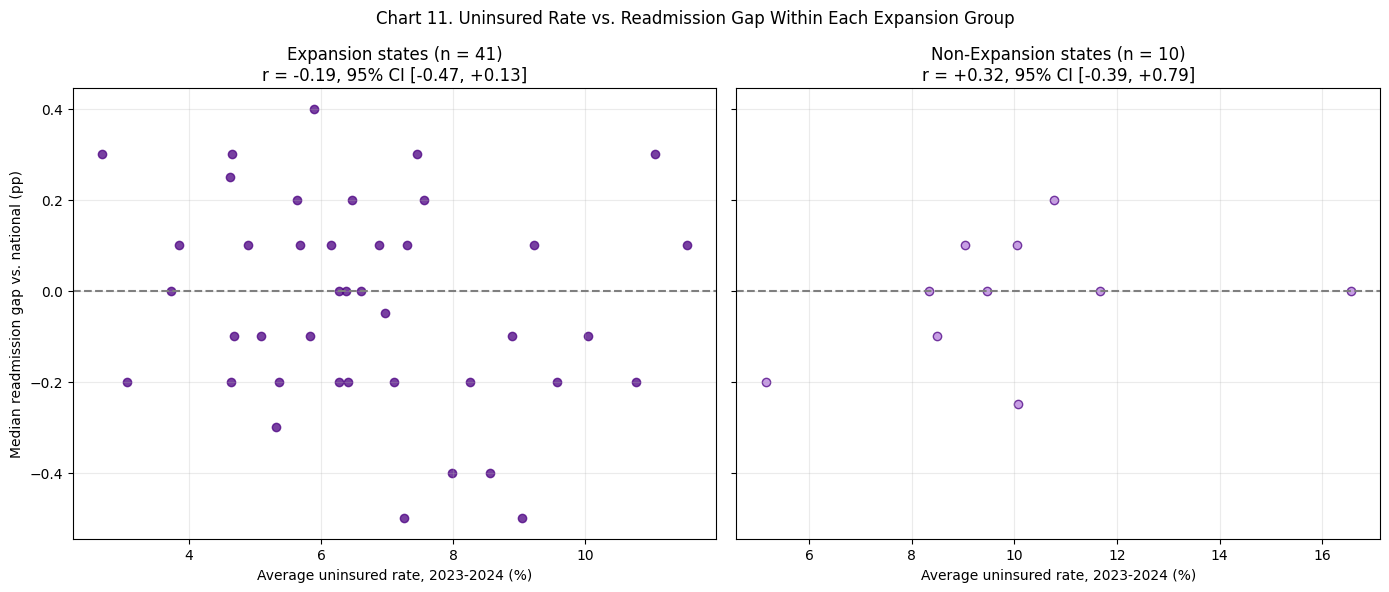

Expansion (n = 41): r = -0.19 [-0.47, +0.13], one-sided p = 0.8795
Non-Expansion (n = 10): r = +0.32 [-0.39, +0.79], one-sided p = 0.1824


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
h9 = {}

for ax, (status, d) in zip(axes, h7_df.groupby("Expansion_Status")):
    r, p = stats.pearsonr(d["Average_Uninsured"], d["Median_Gap"])
    lo, hi = r_ci(r, len(d))
    h9[status] = {"r": r,
                  "lo": lo,
                  "hi": hi,
                  "p": one_sided(p, r),
                  "n": len(d)}

    ax.scatter(d["Average_Uninsured"], d["Median_Gap"],
               color=DARK_PURPLE if status == "Expansion" else LIGHT_PURPLE,
               alpha=0.75, edgecolor=DARK_PURPLE)

    ax.axhline(0, color=GRAY, linestyle="--")
    ax.set_title(f"{status} states (n = {len(d)})\n"
                 f"r = {r:+.2f}, 95% CI [{lo:+.2f}, {hi:+.2f}]")
    ax.set_xlabel("Average uninsured rate, 2023-2024 (%)")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Median readmission gap vs. national (pp)")
fig.suptitle("Chart 11. Uninsured Rate vs. Readmission Gap Within Each Expansion Group")
plt.tight_layout()
plt.show()

for status, v in h9.items():
    print(f"{status} (n = {v['n']}): r = {v['r']:+.2f} [{v['lo']:+.2f}, {v['hi']:+.2f}], "
          f"one-sided p = {v['p']:.4f}")

p9_exp = h9["Expansion"]["p"]
results.append({
    "Hypothesis": "H9",
    "Role": "Secondary",
    "Test": "Pearson r within each group, one-sided",
    "n": f"{h9['Expansion']['n']} / {h9['Non-Expansion']['n']}",
    "Statistic": f"r = {h9['Expansion']['r']:+.2f} (exp.), {h9['Non-Expansion']['r']:+.2f} (non-exp.)",
    "Effect size": f"R-squared = {h9['Expansion']['r'] ** 2:.2f} (exp.)",
    "Raw p": p9_exp,
    "Verdict": None,
})

**Verdict on H9:** Not supported, so we fail to reject H0 (expansion states: r = −0.19, 95% CI [−0.47, +0.13], one-sided p = 0.88, Holm p = 0.88; non-expansion states: r = +0.32, 95% CI [−0.39, +0.79], n = 10).

**So what:** Separating the states by policy does not uncover a hidden link. The non-expansion estimate points in the predicted direction, but with only 10 states its CI runs from −0.39 to +0.79, so it is uninformative.

**Section Takeaway (H8, H9):** The null result is not completely uniform. Chronic conditions show no link (r = −0.14), expansion states show none (r = −0.19), but elective procedures show a modest positive link (r = +0.34, 95% CI[+0.08, +0.56]), mostly through CABG. That is one of several uncorrected sub-group correlations, so it is a lead for future work, not a finding. Non-expansion states (n = 10) are too few to tell. For the funding decision, there is no group where coverage clearly pays off in readmissions.

## 10. Coverage Mix, Hospital Volume, Controls and Consistency

### H10. Medicaid Share as a Poverty Marker

**Question of Interest:** Do states with a larger Medicaid share (a poverty marker) have higher readmission gaps?

**Alternative (Ha):** The average Medicaid share of a state's population is positively correlated with its median readmission gap (r > 0).

**Null (H0):** r is zero or negative.

**Test and Decision Rule:** One-sided Pearson correlation, with and without Puerto Rico; reject H0 if the Holm-adjusted p < 0.05.

,n,Pearson r,95% CI,R-squared,one-sided p
Sample,,,,,
All 52,52,0.447,"[+0.20, +0.64]",0.200,0.000
Without PR,51,0.249,"[-0.03, +0.49]",0.062,0.039


   State  Average_Medicaid
51    PR              47.0
12    NM              33.7


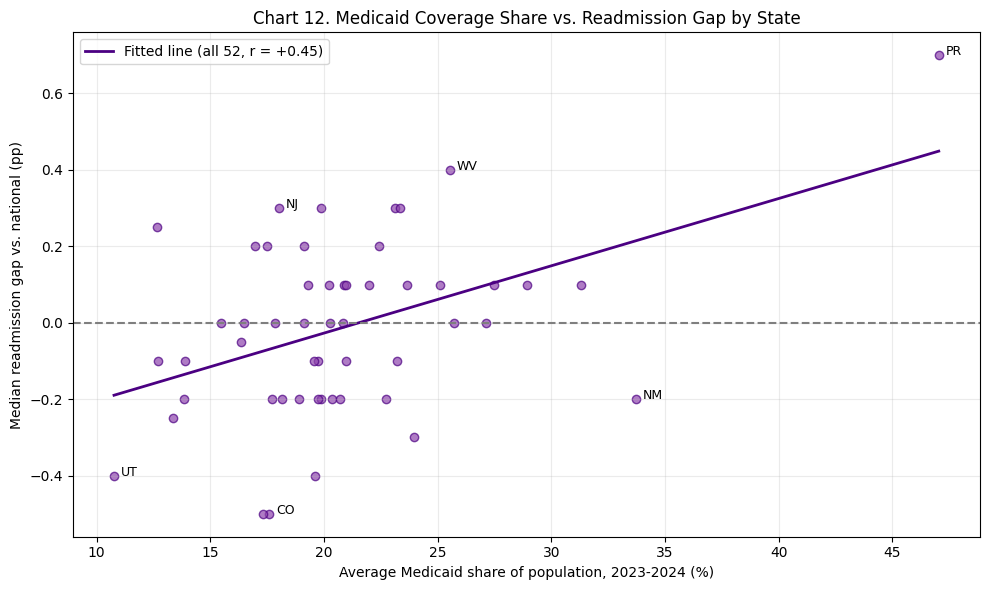

In [ ]:
# H10: Medicaid share vs. readmission gap (Chart 12)

# Average Medicaid share for each state over 2023-2024
recent = insurance[insurance["Year"].isin([2023, 2024])]
medicaid_avg = recent.groupby("State")["Medicaid_%"].mean().reset_index()
medicaid_avg = medicaid_avg.rename(columns={"Medicaid_%": "Average_Medicaid"})

# KFF uses full state names, so we join on State_Name
h10_df = pd.merge(state_gap, medicaid_avg, left_on="State_Name", right_on="State",
                  how="inner", suffixes=("", "_kff"))
h10_df = h10_df.drop(columns="State_kff")

# Pearson r with and without Puerto Rico (PR's Medicaid share is far above every state)
no_pr = h10_df[h10_df["State"] != "PR"]

r_all, p_all = stats.pearsonr(h10_df["Average_Medicaid"], h10_df["Median_Gap"])
r_nopr, p_nopr = stats.pearsonr(no_pr["Average_Medicaid"], no_pr["Median_Gap"])

lo_all, hi_all = r_ci(r_all, len(h10_df))
lo_nopr, hi_nopr = r_ci(r_nopr, len(no_pr))

h10_table = pd.DataFrame({
    "Sample": ["All 52", "Without PR"],
    "n": [len(h10_df), len(no_pr)],
    "Pearson r": [r_all, r_nopr],
    "95% CI": [f"[{lo_all:+.2f}, {hi_all:+.2f}]", f"[{lo_nopr:+.2f}, {hi_nopr:+.2f}]"],
    "R-squared": [r_all ** 2, r_nopr ** 2],
    "one-sided p": [one_sided(p_all, r_all), one_sided(p_nopr, r_nopr)]
})
h10_table = h10_table.set_index("Sample")
display(h10_table.round(3))

r10 = r_all
p10 = one_sided(p_all, r_all)

# Which states have the highest Medicaid share?
top_medicaid = h10_df.sort_values("Average_Medicaid", ascending=False)
print(top_medicaid[["State", "Average_Medicaid"]].head(2).round(1))

# Chart 12: scatter with a fitted regression line
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(data=h10_df, x="Average_Medicaid", y="Median_Gap", ci=None, ax=ax,
            scatter_kws={"color": MEDIUM_PURPLE, "alpha": 0.7, "edgecolor": DARK_PURPLE},
            line_kws={"color": DARK_PURPLE, "linewidth": 2,
                      "label": f"Fitted line (all 52, r = {r10:+.2f})"})

# Label Puerto Rico and a few states at both ends
labeled = h10_df[h10_df["State"].isin(["PR", "NM", "UT", "CO", "WV", "NJ"])]
for i in labeled.index:
    ax.text(labeled.loc[i, "Average_Medicaid"] + 0.3, labeled.loc[i, "Median_Gap"],
            labeled.loc[i, "State"], fontsize=9)
ax.axhline(0, color=GRAY, linestyle="--")
ax.set_xlabel("Average Medicaid share of population, 2023-2024 (%)")
ax.set_ylabel("Median readmission gap vs. national (pp)")
ax.set_title("Chart 12. Medicaid Coverage Share vs. Readmission Gap by State")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

results.append({"Hypothesis": "H10", "Role": "Secondary", "Test": "Pearson r, one-sided",
                "n": len(h10_df),
                "Statistic": f"r = {r10:+.2f} (without PR {r_nopr:+.2f})",
                "Effect size": f"R-squared = {r10 ** 2:.2f}",
                "Raw p": p10, "Verdict": None})

**Verdict on H10: Supported, so we reject H0** (r = +0.45, 95% CI [+0.20, +0.64], R² = 0.20, one-sided p = 0.0005, Holm p = 0.0014). Sensitivity: Puerto Rico, with a 47.0% Medicaid share (next highest: New Mexico at 33.7%), drives much of this. Without it, r = +0.25 (95% CI [−0.03, +0.49], one-sided p = 0.039 before correction).

**So what:** Expansion (H7) is a policy choice, while Medicaid share may largely reflect how many low-income residents a state has (we have no direct poverty variable). The two point in different directions without contradicting each other: being a poorer state goes with somewhat higher readmissions, but the decision to expand does not. This points to social and economic conditions after discharge, which is exactly what care-transition programs target.

### H11. Hospital Volume

**Question of interest:** Do low-volume and high-volume hospitals differ in their readmission gap?

**Alternative (Ha):** The mean gap against the national median differs between low-volume and high-volume hospitals (split at the median volume within each condition).

**Null (H0):** The two means are equal.

**Test and Decision Rule:** Two-sided Welch t-test with Cohen's d; reject H0 and call the difference meaningful only if the Holm-adjusted p < 0.05 and |d| is 0.2 or more.

Low volume:  mean +0.04 pp, SD 0.83, n = 7367
High volume: mean +0.13 pp, SD 1.22, n = 7323
Difference -0.08 pp, d = -0.08, t = -4.92
Two-sided p-value: 8.670858456780557e-07
Rows in the test: 14690


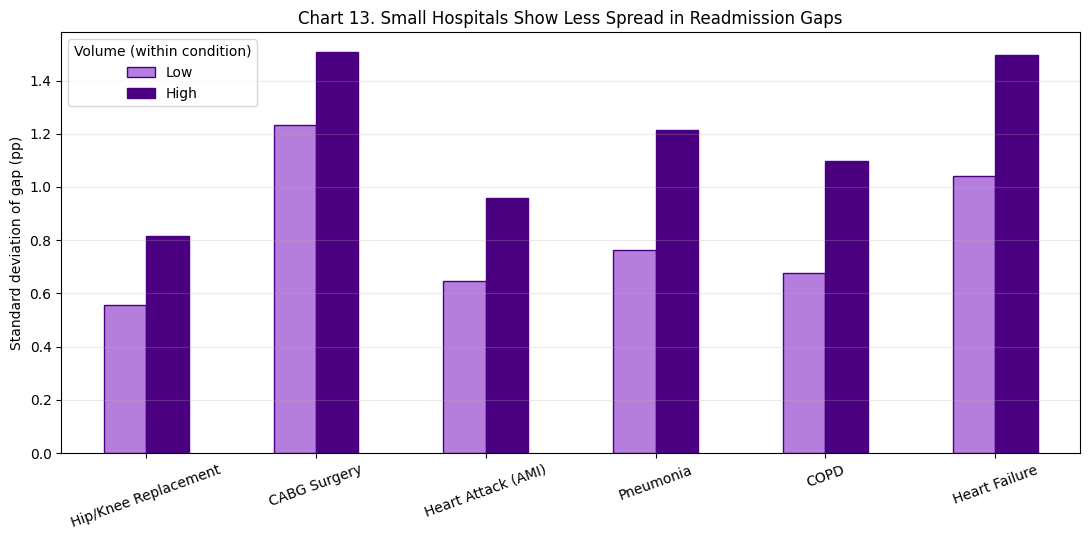

Vol_Tier,High,Low
Measure Label,,
Hip/Knee Replacement,0.81,0.56
CABG Surgery,1.51,1.23
Heart Attack (AMI),0.96,0.65
Pneumonia,1.21,0.76
COPD,1.10,0.68
Heart Failure,1.50,1.04


In [ ]:
# H11: low- vs. high-volume hospitals (Chart 13)

# Split volume at the median WITHIN each condition.
# One median for all conditions would mostly separate heart failure (large counts) from CABG (small counts).
h11 = q3.copy()
h11["Median_Volume"] = h11.groupby("Measure ID")["Denominator"].transform("median")
h11["Vol_Tier"] = "Low"
h11.loc[h11["Denominator"] > h11["Median_Volume"], "Vol_Tier"] = "High"

low = h11.loc[h11["Vol_Tier"] == "Low", "Gap_vs_National"]
high = h11.loc[h11["Vol_Tier"] == "High", "Gap_vs_National"]

# Welch t-test (does not assume equal variances) plus Cohen's d for the size of the difference
t11, p11 = stats.ttest_ind(low, high, equal_var=False)
d11 = cohens_d(low, high)
diff11 = low.mean() - high.mean()

print(f"Low volume:  mean {low.mean():+.2f} pp, SD {low.std():.2f}, n = {len(low)}")
print(f"High volume: mean {high.mean():+.2f} pp, SD {high.std():.2f}, n = {len(high)}")
print(f"Difference {diff11:+.2f} pp, d = {d11:+.2f}, t = {t11:.2f}")
print("Two-sided p-value:", p11)
print("Rows in the test:", len(low) + len(high))

order = hospital_valid.groupby("Measure Label")["Score"].median().sort_values().index

# Chart 13: spread (SD) of the gap for low- vs. high-volume hospitals
# CMS pulls small hospitals toward the national rate, so we expect less spread for low volume
sd_table = h11.pivot_table(values="Gap_vs_National", index="Measure Label",
                           columns="Vol_Tier", aggfunc="std")
sd_table = sd_table.loc[order]

fig, ax = plt.subplots(figsize=(11, 5.5))
sd_table[["Low", "High"]].plot(kind="bar", color=[LIGHT_PURPLE, DARK_PURPLE],
                               edgecolor=DARK_PURPLE, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Standard deviation of gap (pp)")
ax.set_title("Chart 13. Small Hospitals Show Less Spread in Readmission Gaps")
ax.legend(title="Volume (within condition)")
plt.xticks(rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

display(sd_table.round(2))

results.append({"Hypothesis": "H11", "Role": "Secondary", "Test": "Welch t-test, two-sided",
                "n": f"{len(low):,} / {len(high):,}",
                "Statistic": f"t = {t11:.2f}",
                "Effect size": f"{diff11:+.2f} pp, d = {d11:+.2f}",
                "Raw p": p11, "Verdict": None})

**Verdict on H11: Not supported, so we do not call the difference meaningful.** The difference is statistically significant (Welch t = −4.92, Holm p < 0.001) but negligible: low-volume hospitals average +0.04 pp and high-volume hospitals +0.13 pp, a difference of −0.08 pp with d = −0.08, below the 0.2 threshold. The tiny p-value reflects 14,690 non-independent hospital-condition rows, not a meaningful effect.

**So what:** The more useful finding is in Chart 13. In all six conditions, low-volume hospitals have a smaller spread (SD 0.56–1.23 pp vs. 0.81–1.51 pp). CMS scores come from a hierarchical model that pulls small hospitals toward the national rate, so a small hospital's score says less about its true performance. Programs should not rank small hospitals on these scores alone.

### H12 (Exploratory). Controlling for Coverage Mix

**Question of Interest:** After controlling for coverage mix, is the uninsured rate still linked to the readmission gap?

**Alternative (Ha):** Holding Medicaid share, Medicare share and expansion status fixed, a higher uninsured rate goes with a higher readmission gap (positive coefficient).

**Null (H0):** The uninsured-rate coefficient is zero or negative.

**Test and Decision Rule:** OLS regression with robust (HC3) standard errors on 51 states (Puerto Rico excluded) plus a correlation check between the predictors; reject H0 if the one-sided p < 0.05. Exploratory: reported without correction and not part of the Holm family. Regression goes beyond the methods taught in BA780, so it is shown as a table only and no conclusion depends on it.

In [ ]:
# H12 (exploratory): is the uninsured rate still linked to the gap once coverage mix is held fixed?
# Table only, no chart. Puerto Rico is excluded, as in H7.

recent = insurance[insurance["Year"].isin([2023, 2024])]
coverage_means = recent.groupby("State")[["Medicaid_%", "Medicare_%"]].mean().reset_index()
coverage_means = coverage_means.rename(columns={"Medicaid_%": "Average_Medicaid",
                                                "Medicare_%": "Average_Medicare"})

h12_cols = ["State", "State_Name", "Median_Gap", "Average_Uninsured", "Expansion_Status"]
h12_df = pd.merge(h7_df[h12_cols], coverage_means, left_on="State_Name", right_on="State",
                  how="inner", suffixes=("", "_kff"))
h12_df = h12_df.drop(columns="State_kff")

# 0/1 flag: 1 = the state has not expanded Medicaid
h12_df["Non_Expansion"] = 0
h12_df.loc[h12_df["Expansion_Status"] == "Non-Expansion", "Non_Expansion"] = 1

# Quick check that the predictors are not too correlated with each other
predictors = ["Average_Uninsured", "Average_Medicaid", "Average_Medicare", "Non_Expansion"]
print(h12_df[predictors].corr().round(2))

# OLS regression with robust (HC3) standard errors
model = smf.ols("Median_Gap ~ Average_Uninsured + Average_Medicaid + Average_Medicare + Non_Expansion",
                data=h12_df).fit(cov_type="HC3")

ci12 = model.conf_int()
coef_table = pd.DataFrame({"Coefficient": model.params,
                           "95% CI low": ci12[0],
                           "95% CI high": ci12[1],
                           "p (two-sided)": model.pvalues})
display(coef_table.round(3))

# We predicted a positive uninsured coefficient, so the test is one-sided
b12 = model.params["Average_Uninsured"]
lo12 = ci12.loc["Average_Uninsured", 0]
hi12 = ci12.loc["Average_Uninsured", 1]
p12 = one_sided(model.pvalues["Average_Uninsured"], b12)

print(f"n = {int(model.nobs)} states, R-squared = {model.rsquared:.2f}")
print(f"Uninsured coefficient: {b12:+.3f} pp per 1 pp uninsured, "
      f"95% CI [{lo12:+.3f}, {hi12:+.3f}], one-sided p = {p12:.4f}")

if p12 < 0.05:
    verdict12 = "Supported"
else:
    verdict12 = "Not supported"
print("Verdict on H12:", verdict12)

results.append({"Hypothesis": "H12", "Role": "Exploratory", "Test": "OLS, HC3 robust SE",
                "n": int(model.nobs),
                "Statistic": f"b = {b12:+.3f} pp per 1 pp uninsured",
                "Effect size": f"95% CI [{lo12:+.3f}, {hi12:+.3f}], R-squared = {model.rsquared:.2f}",
                "Raw p": p12, "Verdict": verdict12})

                   Average_Uninsured  Average_Medicaid  Average_Medicare  \
Average_Uninsured               1.00             -0.18             -0.16   
Average_Medicaid               -0.18              1.00             -0.08   
Average_Medicare               -0.16             -0.08              1.00   
Non_Expansion                   0.50             -0.27              0.03   

                   Non_Expansion  
Average_Uninsured           0.50  
Average_Medicaid           -0.27  
Average_Medicare            0.03  
Non_Expansion               1.00  


,Coefficient,95% CI low,95% CI high,p (two-sided)
Intercept,-0.443,-1.137,0.251,0.211
Average_Uninsured,-0.006,-0.037,0.025,0.705
Average_Medicaid,0.013,-0.003,0.029,0.114
Average_Medicare,0.012,-0.016,0.039,0.400
Non_Expansion,0.073,-0.093,0.240,0.389


n = 51 states, R-squared = 0.09
Uninsured coefficient: -0.006 pp per 1 pp uninsured, 95% CI [-0.037, +0.025], one-sided p = 0.6476
Verdict on H12: Not supported


**Verdict on H12 (Exploratory): Not supported, so we fail to reject H0** (uninsured coefficient −0.006 pp per 1 pp, 95% CI [−0.037, +0.025], one-sided p = 0.65, n = 51, R-squared = 0.09).

**So what:** Holding Medicaid share, Medicare share and expansion status constant, the uninsured rate is still not linked to the readmission gap. The null result in H6 is not hiding behind differences in coverage mix. This regression goes beyond the methods taught in BA780 and is shown as a table only; no conclusion depends on it. The population-mismatch limit (Limitation 1) still applies.

### H13 (Supporting). Consistency across conditions

**Question of Interest:** Are the same states above (or below) the national readmission rate on different conditions?

**Alternative (Ha):** The average correlation between the state gaps of different conditions is positive.

**Null (H0):** The average correlation is zero or negative.

**Test and Decision Rule:** The state median gaps for the six conditions are correlated in pairs (15 pairs); reject H0 if the whole bootstrap 95% CI of the average correlation (states resampled 2,000 times) is above 0. The average for the four medical conditions (heart attack, heart failure, COPD, pneumonia) is reported separately. Supporting analysis: no p-value, not part of the Holm family.

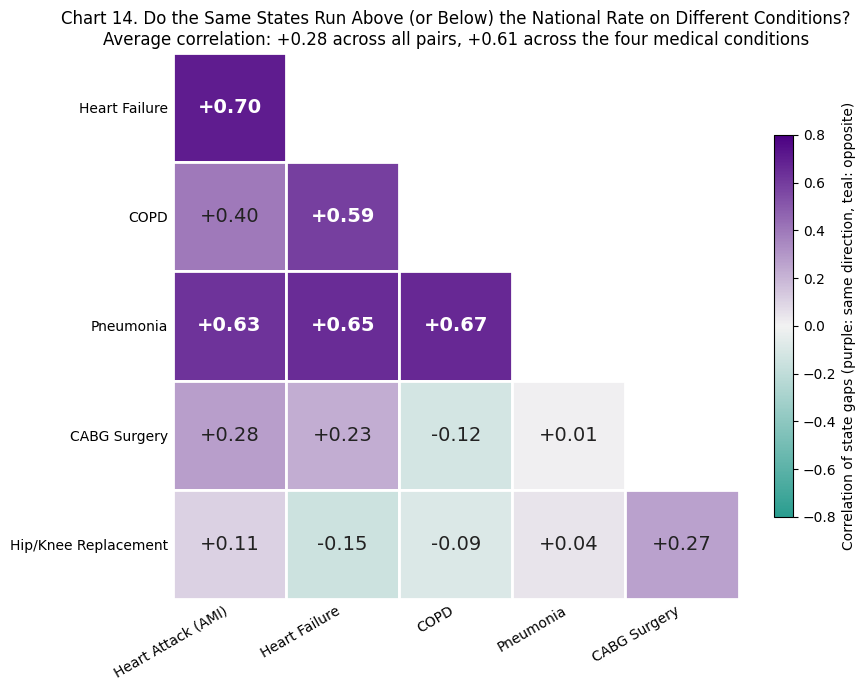

States with all six conditions: 52
Average pairwise r, all six conditions: +0.28, bootstrap 95% CI [+0.17, +0.40]
Average pairwise r, four medical conditions: +0.61, bootstrap 95% CI [+0.46, +0.72]
CABG vs. hip/knee: r = +0.27
H13 supported (rule: whole 95% CI above 0)


In [ ]:
# H13 (supporting): are states consistently above or below the national rate across conditions? - Chart 14
medical = ["Heart Attack (AMI)", "Heart Failure", "COPD", "Pneumonia"]
surgical = ["CABG Surgery", "Hip/Knee Replacement"]
conditions = medical + surgical

# One row per geography, one column per condition: that state's median gap for the condition
gap_matrix = (q3.pivot_table(index="State", columns="Measure Label", values="Gap_vs_National", aggfunc="median")
              [conditions].dropna())
corr = gap_matrix.corr()


def mean_pairwise_r(frame, cols):
    """Average correlation over all pairs of the listed conditions."""
    c = frame[cols].corr().to_numpy()
    return c[np.triu_indices(len(cols), k=1)].mean()


mean_all = mean_pairwise_r(gap_matrix, conditions)
mean_med = mean_pairwise_r(gap_matrix, medical)

# Bootstrap: resample the states 2,000 times to get a 95% confidence interval for each average
rng = np.random.default_rng(42)
boot_all, boot_med = [], []
for _ in range(2000):
    sample = gap_matrix.sample(n=len(gap_matrix), replace=True, random_state=int(rng.integers(1_000_000_000)))
    boot_all.append(mean_pairwise_r(sample, conditions))
    boot_med.append(mean_pairwise_r(sample, medical))
lo_all, hi_all = np.percentile(boot_all, [2.5, 97.5])
lo_med, hi_med = np.percentile(boot_med, [2.5, 97.5])

# Chart 14: correlation of state gaps between every pair of conditions
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cmap = LinearSegmentedColormap.from_list("div", ["#2A9D8F", "#F2F2F2", DARK_PURPLE])
norm = TwoSlopeNorm(vmin=-0.8, vcenter=0, vmax=0.8)
n = len(conditions)
fig, ax = plt.subplots(figsize=(9, 7))
for i in range(1, n):
    for j in range(i):
        r = corr.loc[conditions[i], conditions[j]]
        ax.add_patch(plt.Rectangle((j, n - 1 - i), 1, 1, facecolor=cmap(norm(r)), edgecolor="white", linewidth=2))
        ax.text(j + 0.5, n - 1 - i + 0.5, f"{r:+.2f}", ha="center", va="center", fontsize=14,
                fontweight="bold" if abs(r) >= 0.4 else "normal", color="white" if abs(r) > 0.5 else "#222222")
ax.set_xlim(0, n - 1)
ax.set_ylim(0, n - 1)
ax.set_xticks([j + 0.5 for j in range(n - 1)], conditions[:-1], rotation=30, ha="right")
ax.set_yticks([n - 1 - i + 0.5 for i in range(1, n)], conditions[1:])
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Chart 14. Do the Same States Run Above (or Below) the National Rate on Different Conditions?\n"
             f"Average correlation: {mean_all:+.2f} across all pairs, {mean_med:+.2f} across the four medical conditions",
             fontsize=12)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=ax, shrink=0.7)
cbar.set_label("Correlation of state gaps (purple: same direction, teal: opposite)")
plt.tight_layout()
plt.show()

print(f"States with all six conditions: {len(gap_matrix)}")
print(f"Average pairwise r, all six conditions: {mean_all:+.2f}, bootstrap 95% CI [{lo_all:+.2f}, {hi_all:+.2f}]")
print(f"Average pairwise r, four medical conditions: {mean_med:+.2f}, bootstrap 95% CI [{lo_med:+.2f}, {hi_med:+.2f}]")
print(f"CABG vs. hip/knee: r = {corr.loc['CABG Surgery', 'Hip/Knee Replacement']:+.2f}")
print("H13 supported" if lo_all > 0 else "H13 not supported", "(rule: whole 95% CI above 0)")
results.append({"Hypothesis": "H13", "Role": "Supporting", "Test": "Average pairwise r, bootstrap CI",
                "n": len(gap_matrix), "Statistic": f"mean r = {mean_all:+.2f}",
                "Effect size": f"95% CI [{lo_all:+.2f}, {hi_all:+.2f}]", "Raw p": np.nan,
                "Verdict": "Supported" if lo_all > 0 else "Not supported"})

**Verdict on H13: Supported, so we reject H0** (average pairwise r = +0.28 across all six conditions, bootstrap 95% CI [+0.17, +0.40]; across the four medical conditions r = +0.61, 95% CI [+0.46, +0.72]; n = 52 geographies). The two surgical conditions do not line up with the medical ones, and CABG and hip/knee replacement correlate only weakly (r = +0.27).

**So what:** States are not randomly good or bad on each condition. A state above the national rate on pneumonia, COPD or heart failure tends to be above on the others, so the four medical conditions move together. That points to something about the state as a whole (discharge and follow-up practice, community resources, patient mix) rather than a condition-specific quirk, which is the kind of problem care-transition programs target. It does not show what the cause is, and the Medicare-based scores and small hospital counts in some states (Limitation 6) still apply.

### Putting it together: Where to focus first

**Question of interest:** Which high-Medicaid states have the highest readmission gaps and should care-transition support reach first?

H10 found that the readmission gap follows poverty (Medicaid share), not the uninsured rate. The chart below turns that into a short list: among the states with an above-median Medicaid share, the ten with the highest readmission gap. It is a screening list for care-transition support, not a test. Puerto Rico is left out of the list because it is a territory and an extreme outlier on Medicaid share (47%); it has the highest gap of all 52 (+0.70 pp).


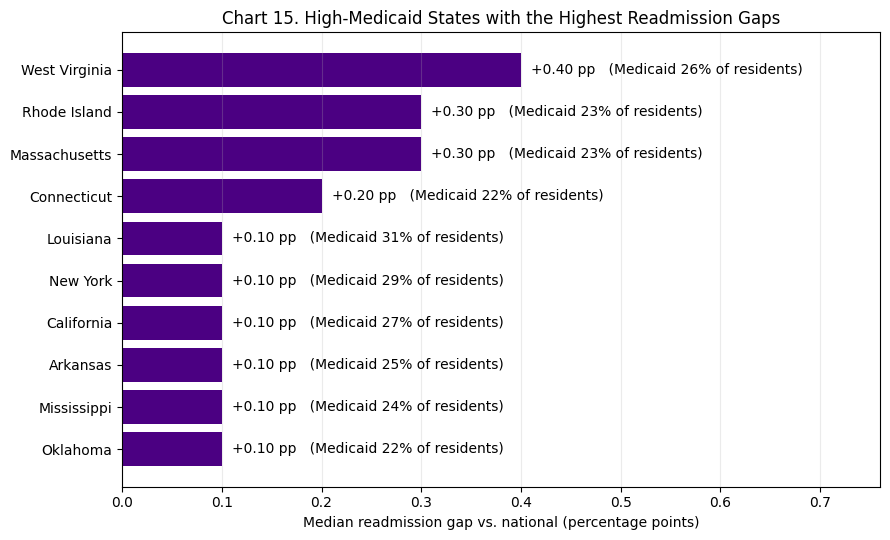

Medicaid-share cut-off (median of 52 geographies): 19.9%


In [ ]:
# Chart 15: states to look at first = high Medicaid share AND highest readmission gap
# Puerto Rico is left out of this list (it is a territory with a 47% Medicaid share, far above any state)
med_cut = h10_df["Average_Medicaid"].median()
watch = (h10_df[(h10_df["Average_Medicaid"] >= med_cut) & (h10_df["State"] != "PR")]
         .sort_values(["Median_Gap", "Average_Medicaid"], ascending=False).head(10)
         .sort_values(["Median_Gap", "Average_Medicaid"]))

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(watch["State_Name"], watch["Median_Gap"], color=DARK_PURPLE)
for y, (g, m) in enumerate(zip(watch["Median_Gap"], watch["Average_Medicaid"])):
    ax.text(g + 0.01, y, f"+{g:.2f} pp   (Medicaid {m:.0f}% of residents)", va="center", fontsize=10)
ax.set_xlim(0, watch["Median_Gap"].max() * 1.9)
ax.set_xlabel("Median readmission gap vs. national (percentage points)")
ax.set_title("Chart 15. High-Medicaid States with the Highest Readmission Gaps")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()
print(f"Medicaid-share cut-off (median of 52 geographies): {med_cut:.1f}%")


### Puerto Rico check: Do the results depend on it?

**Question of Interest:** Do any of our verdicts change if Puerto Rico is removed?

We considered whether Puerto Rico should be in the analysis at all. We keep it in the descriptive work because it is in both CMS and KFF and is scored under the same readmission program, but we test whether it matters. The table repeats the headline numbers with and without it. No verdict flips: H2's range narrows to 0.90 pp (still under 1.5 pp), H6 stays null, and H10 weakens from r = +0.45 to +0.25 (the one result that leans on Puerto Rico).


In [ ]:
# Puerto Rico check: Headline results for all 52 geographies vs. the 51 without Puerto Rico
gap_all = state_gap.copy()
unins_all = state_insurance[["State", "Average_Uninsured"]].copy()

def pr_rows(drop_pr):
    g = gap_all[gap_all["State"] != "PR"] if drop_pr else gap_all
    u = unins_all[unins_all["State"] != "Puerto Rico"] if drop_pr else unins_all
    m6 = pd.merge(g, u, left_on="State_Name", right_on="State", how="inner", suffixes=("", "_u"))
    m10 = h10_df[h10_df["State"] != "PR"] if drop_pr else h10_df
    r6_, _ = stats.pearsonr(m6["Average_Uninsured"], m6["Median_Gap"])
    r10_, _ = stats.pearsonr(m10["Average_Medicaid"], m10["Median_Gap"])
    return [f"{g['Median_Gap'].max() - g['Median_Gap'].min():.2f} pp",
            f"{u['Average_Uninsured'].max() / u['Average_Uninsured'].min():.1f}x",
            f"{r6_:+.2f}", f"{r10_:+.2f}"]

pr_table = pd.DataFrame({"All 52": pr_rows(False), "Without Puerto Rico (51)": pr_rows(True)},
                        index=["H2: range of state gaps", "H3: highest / lowest uninsured rate",
                               "H6: uninsured rate vs. gap (r)", "H10: Medicaid share vs. gap (r)"])
display(pr_table)


,All 52,Without Puerto Rico (51)
H2: range of state gaps,1.20 pp,0.90 pp
H3: highest / lowest uninsured rate,6.2x,6.2x
H6: uninsured rate vs. gap (r),-0.11,-0.08
H10: Medicaid share vs. gap (r),+0.45,+0.25


**Section Takeaway (H10 to H13):** What does line up with readmissions is poverty (Medicaid share), not coverage; small hospitals' scores are shrunk toward the national rate, so they should not be ranked on these scores alone; and the exploratory multivariable check (H12) is reported in its own table without driving the conclusion. For the funding decision this points toward care-transition support aimed at high-poverty areas rather than coverage expansion as a readmission program. States that run above the national rate on one medical condition tend to run above on the others (H13), which supports aiming care-transition support at those states.

## 11. Results Summary

The table below is built from the numbers computed in each section. Secondary p-values are Holm-adjusted.

In [ ]:
# Holm correction for the secondary tests that have a p-value (H5, H9, H10, H11); H8 uses CIs instead
secondary = {row["Hypothesis"]: row["Raw p"] for row in results
             if row["Role"] == "Secondary" and not pd.isnull(row["Raw p"])}
m = len(secondary)
holm = {}
running = 0
for i, (h, p) in enumerate(sorted(secondary.items(), key=lambda kv: kv[1])):
    running = max(running, min(1, p * (m - i)))
    holm[h] = running

summary = pd.DataFrame(results)
summary["Holm p"] = summary["Hypothesis"].map(holm)
for i, row in summary.iterrows():
    if row["Hypothesis"] in holm:
        summary.loc[i, "Verdict"] = "Supported" if row["Holm p"] < 0.05 else "Not supported"

# H11's decision rule also needs a non-trivial effect: |d| of 0.2 or more
if holm["H11"] < 0.05 and abs(d11) < 0.2:
    summary.loc[summary["Hypothesis"] == "H11", "Verdict"] = "Not supported (significant but negligible, |d| < 0.2)"

order_h = ["H1", "H2", "H3", "H4", "H5", "H6", "H6b", "H7", "H8", "H9", "H10", "H11", "H12", "H13"]
summary = summary.set_index("Hypothesis").loc[order_h].reset_index()
summary["Raw p"] = summary["Raw p"].map(lambda v: "" if pd.isnull(v) else f"{v:.4f}")
summary["Holm p"] = summary["Holm p"].map(lambda v: "" if pd.isnull(v) else f"{v:.4f}")

pd.set_option("display.max_colwidth", None)
summary[["Hypothesis", "Role", "Test", "n", "Statistic", "Effect size", "Raw p", "Holm p", "Verdict"]]

,Hypothesis,Role,Test,n,Statistic,Effect size,Raw p,Holm p,Verdict
0,H1,Descriptive,Median range / median IQR,14701,ratio = 13.5x,,,,Supported
1,H2,Descriptive,Range of state median gaps,52,range = 1.20 pp,,,,Supported
2,H3,Descriptive,Max / min uninsured rate,52,ratio = 6.2x,,,,Supported
3,H4,Descriptive,Records per condition,6,"min = 938, max = 3,758",,,,Supported
4,H5,Secondary,"Welch t-test, one-sided",41 vs 10,t = -3.31,"-3.24 pp, d = -1.41",0.0033,0.0066,Supported
5,H6,Primary,"Pearson r, one-sided (Spearman check)",52,r = -0.11 (without PR -0.08),R-squared = 0.01,0.7844,,Not supported
6,H6b,Robustness,Pearson + Spearman,52,"r = -0.08, rho = -0.00",R-squared = 0.01,0.7034,,Same sign as H6
7,H7,Primary,"Welch t-test, one-sided",41 vs 10,t = -0.25,"-0.01 pp, d = -0.07",0.4009,,Not supported
8,H8,Secondary,Two Pearson r with 95% CIs,52 / 52,r = -0.14 vs +0.34,"CIs [-0.40, +0.13] vs [+0.08, +0.56]",,,No evidence of a difference
9,H9,Secondary,"Pearson r within each group, one-sided",41 / 10,"r = -0.19 (exp.), +0.32 (non-exp.)",R-squared = 0.04 (exp.),0.8795,0.8795,Not supported


### Number Audit

Every number quoted in the text above is checked here against the value computed in this notebook. A FAIL means the text and the code disagree, so the text must be corrected.

In [ ]:
# Number audit: Every number quoted in the Markdown text next to the value computed above

rows = [  # (what the text says, value quoted in the text, value computed in this notebook, tolerance)
    ("CMS raw rows", 67060, len(unplanned_visit_hp), 0),
    ("Readmission rows", 28740, len(hospital), 0),
    ("Usable rows", 14701, len(hospital_valid), 0),
    ("Usable share (%)", 51.2, len(hospital_valid) / len(hospital) * 100, 0.05),
    ("Suppressed rows", 14039, excluded, 0),
    ("H1 ratio", 13.5, h1_ratio, 0.05),
    ("H1 range of condition medians (pp)", 15.5, across_range, 0.05),
    ("H1 typical within-condition IQR (pp)", 1.1, typical_within_iqr, 0.05),
    ("H2 lowest state gap (pp)", -0.50, state_gap["Median_Gap"].min(), 0.005),
    ("H2 highest state gap (pp)", 0.70, state_gap["Median_Gap"].max(), 0.005),
    ("H2 range (pp)", 1.20, h2_range, 0.005),
    ("H3 lowest uninsured rate (%)", 2.69, lowest["Average_Uninsured"], 0.005),
    ("H3 highest uninsured rate (%)", 16.56, highest["Average_Uninsured"], 0.005),
    ("H3 ratio", 6.2, h3_ratio, 0.05),
    ("H4 CABG usable records", 938, measure_counts.loc["CABG Surgery", "Usable Records"], 0),
    ("H4 pneumonia usable records", 3758, measure_counts.loc["Pneumonia", "Usable Records"], 0),
    ("H5 expansion mean uninsured (%)", 6.72, exp5.mean(), 0.005),
    ("H5 non-expansion mean uninsured (%)", 9.96, non5.mean(), 0.005),
    ("H5 difference (pp)", -3.24, exp5.mean() - non5.mean(), 0.005),
    ("H5 Cohen's d", -1.41, d5, 0.005),
    ("H5 Welch t", -3.31, t5, 0.005),
    ("H5 one-sided p", 0.0033, p5, 0.00005),
    ("H5 Holm p", 0.0066, holm["H5"], 0.00005),
    ("H6 Pearson r", -0.11, r6, 0.005),
    ("H6 CI low", -0.37, r_ci(r6, len(h6_df))[0], 0.005),
    ("H6 CI high", 0.17, r_ci(r6, len(h6_df))[1], 0.005),
    ("H6 r without PR", -0.08, h6_table.loc["Without PR", "Pearson r"], 0.005),
    ("H6b r", -0.08, r6b, 0.005),
    ("H7 Cohen's d", -0.07, d7, 0.005),
    ("H7 one-sided p", 0.40, p7, 0.005),
    ("H7 difference (pp)", -0.01, exp.mean() - non.mean(), 0.005),
    ("H8 chronic r", -0.14, rc, 0.005),
    ("H8 elective r", 0.34, re, 0.005),
    ("H9 r, expansion states", -0.19, h9["Expansion"]["r"], 0.005),
    ("H9 r, non-expansion states", 0.32, h9["Non-Expansion"]["r"], 0.005),
    ("H10 r", 0.45, r10, 0.005),
    ("H10 Holm p", 0.0014, holm["H10"], 0.00005),
    ("H10 r without PR", 0.25, h10_table.loc["Without PR", "Pearson r"], 0.005),
    ("PR Medicaid share (%)", 47.0, float(h10_df.loc[h10_df["State"] == "PR", "Average_Medicaid"].iloc[0]), 0.05),
    ("H11 Cohen's d", -0.08, d11, 0.005),
    ("H11 rows in test", 14690, len(low) + len(high), 0),
    ("KFF state-year rows", 156, len(insurance), 0),
    ("States per KFF year", 52, int(insurance.groupby("Year")["State"].count().min()), 0),
    ("H1 hip/knee median (%)", 5.8, condition_medians["Hip/Knee Replacement"], 0.05),
    ("H1 heart failure median (%)", 21.3, condition_medians["Heart Failure"], 0.05),
    ("H4 states reporting (minimum)", 52, int(measure_counts["States Reporting"].min()), 0),
    ("False-positive chance, 8 p-value tests (%)", 34, (1 - 0.95 ** 8) * 100, 0.5),
    ("H6 R-squared", 0.01, r6 ** 2, 0.005),
    ("H6 one-sided p", 0.78, p6, 0.005),
    ("H6 p without PR", 0.70, p6_noPR, 0.005),
    ("H6 Spearman rho", -0.10, h6_table.loc["All 52", "Spearman rho"], 0.005),
    ("H6b CI low", -0.34, r_ci(r6b, len(h6b_df))[0], 0.005),
    ("H6b CI high", 0.20, r_ci(r6b, len(h6b_df))[1], 0.005),
    ("H6b Spearman rho", 0.0, rho6b, 0.005),
    ("H7 Welch t", -0.25, t7, 0.005),
    ("H7 expansion n", 41, len(exp), 0),
    ("H7 non-expansion n", 10, len(non), 0),
    ("H7 expansion median gap (pp)", 0.0, exp.median(), 0.005),
    ("H7 non-expansion median gap (pp)", 0.0, non.median(), 0.005),
    ("H7 difference without NC, SD (pp)", -0.01, exp_s.mean() - non.mean(), 0.005),
    ("H7 p without NC, SD", 0.44, one_sided(p7s_two, t7s, expect_positive=False), 0.005),
    ("H8 chronic CI low", -0.40, loc, 0.005),
    ("H8 chronic CI high", 0.13, hic, 0.005),
    ("H8 elective CI low", 0.08, loe, 0.005),
    ("H8 elective CI high", 0.56, hie, 0.005),
    ("H8 CABG r", 0.40, float(r_by_condition.set_index("Condition").loc["CABG Surgery", "r"]), 0.005),
    ("H8 CABG CI low", 0.14, float(r_by_condition.set_index("Condition").loc["CABG Surgery", "low"]), 0.005),
    ("H8 CABG CI high", 0.60, float(r_by_condition.set_index("Condition").loc["CABG Surgery", "high"]), 0.005),
    ("H9 expansion CI low", -0.47, h9["Expansion"]["lo"], 0.005),
    ("H9 expansion CI high", 0.13, h9["Expansion"]["hi"], 0.005),
    ("H9 expansion one-sided p", 0.88, h9["Expansion"]["p"], 0.005),
    ("H9 Holm p", 0.88, holm["H9"], 0.005),
    ("H9 non-expansion CI low", -0.39, h9["Non-Expansion"]["lo"], 0.005),
    ("H9 non-expansion CI high", 0.79, h9["Non-Expansion"]["hi"], 0.005),
    ("H9 non-expansion n", 10, h9["Non-Expansion"]["n"], 0),
    ("H10 CI low", 0.20, r_ci(r10, len(h10_df))[0], 0.005),
    ("H10 CI high", 0.64, r_ci(r10, len(h10_df))[1], 0.005),
    ("H10 R-squared", 0.20, r10 ** 2, 0.005),
    ("H10 one-sided p", 0.0005, p10, 0.00005),
    ("H10 p without PR", 0.039, h10_table.loc["Without PR", "one-sided p"], 0.0005),
    ("H10 CI low without PR", -0.03, r_ci(h10_table.loc["Without PR", "Pearson r"], len(h10_df) - 1)[0], 0.005),
    ("H10 CI high without PR", 0.49, r_ci(h10_table.loc["Without PR", "Pearson r"], len(h10_df) - 1)[1], 0.005),
    ("New Mexico Medicaid share (%)", 33.7, float(h10_df.loc[h10_df["State"] == "NM", "Average_Medicaid"].iloc[0]), 0.05),
    ("H11 Welch t", -4.92, t11, 0.005),
    ("H11 low-volume mean gap (pp)", 0.04, low.mean(), 0.005),
    ("H11 high-volume mean gap (pp)", 0.13, high.mean(), 0.005),
    ("H11 difference (pp)", -0.08, low.mean() - high.mean(), 0.005),
    ("H11 low-volume SD, smallest (pp)", 0.56, sd_table["Low"].min(), 0.005),
    ("H11 low-volume SD, largest (pp)", 1.23, sd_table["Low"].max(), 0.005),
    ("H11 high-volume SD, smallest (pp)", 0.81, sd_table["High"].min(), 0.005),
    ("H11 high-volume SD, largest (pp)", 1.51, sd_table["High"].max(), 0.005),
    ("H13 average pairwise r, all six", 0.28, mean_all, 0.005),
    ("H13 CI low, all six", 0.17, lo_all, 0.01),
    ("H13 CI high, all six", 0.40, hi_all, 0.01),
    ("H13 average pairwise r, medical four", 0.61, mean_med, 0.005),
    ("H13 CI low, medical four", 0.46, lo_med, 0.01),
    ("H13 CI high, medical four", 0.72, hi_med, 0.01),
    ("H13 CABG vs. hip/knee r", 0.27, corr.loc["CABG Surgery", "Hip/Knee Replacement"], 0.005),
]
audit = pd.DataFrame(rows, columns=["Number quoted in text", "Quoted", "Computed", "Tolerance"])
audit["Computed"] = audit["Computed"].astype(float).round(4)
audit["Status"] = np.where((audit["Quoted"] - audit["Computed"]).abs() <= audit["Tolerance"] + 1e-9, "PASS", "FAIL")
# Print only the problems (the full table stays in the variable `audit`)
display(audit.loc[audit["Status"] == "FAIL", ["Number quoted in text", "Quoted", "Computed", "Status"]])
n_fail = int((audit["Status"] == "FAIL").sum())
print(f"{len(audit) - n_fail} of {len(audit)} quoted numbers verified"
      + ("" if n_fail == 0 else f" | {n_fail} FAIL: correct the text (not the audit) for those rows"))

,Number quoted in text,Quoted,Computed,Status


98 of 98 quoted numbers verified


**Reading the Table:** All four descriptive checks (H1–H4) hold, and expansion states do have clearly lower uninsured rates (H5). Both primary tests (H6, H7) are not supported, and the robustness check (H6b) agrees with H6. The supporting analysis (H13) finds that state gaps are consistent across the medical conditions. Of the secondary tests, only H10 is supported, and it is partly driven by Puerto Rico. H11 is statistically significant but too small to matter. H12 (exploratory, uncorrected) is shown for completeness, and no conclusion depends on it.

## 12. Challenges

| Data challenge | How we handled it |
|---|---|
| CMS `Score` and `Denominator` columns were stored as text because they contain "Not Available" | Counted the text values with `value_counts()`, converted with `pd.to_numeric(errors="coerce")`, and kept only rows with a score and a positive denominator |
| 48.8% of readmission records (14,039 of 28,740) were suppressed by CMS for small case counts | Documented the exclusion and checked that all six conditions still cover all 52 geographies (H4) |
| Raw scores mix conditions with very different typical rates (5.8% to 21.3%) | Compared each hospital with the national median for the same condition using `groupby().transform()` (justified by H1) |
| CMS uses state codes (MA), KFF uses names (Massachusetts) | Joined the course's `state-abbrevs.csv` lookup table with `pd.merge(validate="many_to_one")`, added Puerto Rico, and confirmed 52 matches with an outer join (`indicator=True`) |
| KFF files contain note rows and a national total below the state rows | Dropped rows with no `Total` and the "United States" row; converted head counts to % of population |
| CMS pools Jul 2023–Jun 2025, while KFF is annual | Used the 2023–2024 KFF average as the coverage measure |
| Puerto Rico is an outlier (largest gap, 47% Medicaid share) and is outside the ACA expansion framework | Reported H6 and H10 with and without PR, and excluded PR from H5, H7, H9 and H12 |
| The CMS state file mixes readmission and other measures, and some measure rows have no classified hospitals | Kept only `READM_30_` rows and rows with at least one classified hospital before computing the "worse than national" share (H6b) |
| A pooled volume split would mostly separate heart-failure (large) from CABG (small) records | Split volume at the median **within each condition** (H11) |
| NC (Dec 2023) and SD (Jul 2023) expanded Medicaid inside the CMS reporting window | Re-ran H7 without them (same answer) |
| Hospital-level rows are not independent (a hospital contributes up to six conditions) | Read H1 and H11 mainly by effect size (ratio, Cohen's d), not by p-value |

**Takeaway:** Every challenge was handled in code and checked by an output (a count, a printed match or a re-run), so the results in Sections 5 to 10 do not depend on an unverified cleaning step.

## 13. Limitations

| # | Limitation | Impact | Mitigation |
|---|---|---|---|
| 1 | **Population mismatch.** CMS readmission measures are built on Medicare patients (mostly 65+ and almost all insured), while KFF coverage describes the whole population. | High | Null results are read as "weak proxy", not "no effect". Expansion status (H7) and Medicaid share (H10) are partial fixes. |
| 2 | **Ecological level.** 52 state aggregates cannot show that any patient's coverage changes their own readmission risk. | High for policy claims | Report associations only. H9 controls one confounder by splitting the states. |
| 3 | **Limited multivariable control.** H12 adds a first regression (uninsured, Medicaid, Medicare, expansion status); income, age and hospital mix are still not held constant. | Moderate | Stated plainly; a richer model is the next step. |
| 4 | **Timing.** CMS pools Jul 2023–Jun 2025, KFF is annual; NC (Dec 2023) and SD (Jul 2023) expanded inside the window. | Low to moderate | Used the 2023–2024 KFF average; H7 re-run without NC and SD gives the same answer. |
| 5 | **Suppressed scores and shrinkage.** 48.8% of records are suppressed, and small hospitals are pulled toward the national rate. | Moderate | Follows CMS rules; interpret H11 and the CABG results with this in mind. |
| 6 | **Small groups.** Non-expansion n = 10; DC and Delaware have fewer than 10 hospitals. | Moderate | Report CIs and Cohen's d; do not over-read p in H7 and H9. |
| 7 | **No direct poverty measure.** Medicaid share (H10) is only a possible stand-in for poverty; it also reflects eligibility rules and enrollment. | Moderate | Worded as a "possible poverty marker"; the next step adds income data. |
| 8 | **Puerto Rico.** It is an outlier (Medicaid share 47.0%) and is outside the ACA expansion framework. | Moderate | Kept in descriptive tests, excluded from H5, H7, H9 and H12, and H6 and H10 are reported with and without it. |

**Net effect:** The descriptive findings (H1–H4) stand on their own. H5–H12 show associations through a state-level coverage proxy. That is enough to say where readmission money should **not** be targeted, but not enough to say whether insurance affects an individual patient's readmission risk.

## 14. Conclusion and Recommendation

**Decision:** On this evidence, do not justify coverage expansion by its effect on readmissions. Care-transition programs are the better-supported use of readmission money, based on published evidence (references 8 and 9), not on our own data, which did not test them.

**What the Data Says:**
1. Readmission gaps between states are narrow (1.20 pp in total, H2), while uninsured rates differ six-fold (H3).
2. The uninsured rate does not track the readmission gap (H6: r = −0.11, R² = 0.01). This holds without Puerto Rico and with CMS's own "worse than national" classification (H6b).
3. Medicaid-expansion states have much lower uninsured rates (H5: 6.72% vs. 9.96%, d = −1.41), yet perform like non-expansion states on readmissions (H7: difference −0.01 pp, d = −0.07), including when the two late-expansion states (NC, SD) are removed.
4. No hidden coverage link appears by policy group (H9). By condition (H8), chronic conditions show none and elective procedures show a modest positive link (r = +0.34, driven by CABG), which we treat as a lead, not a finding.
5. What does line up is the Medicaid **share**, a possible poverty marker (H10: r = +0.45, weaker without Puerto Rico), which points to social and economic needs after discharge.
6. Controlling for Medicaid share, Medicare share and expansion status, the uninsured rate is still not linked to the gap (H12: −0.006 pp per 1 pp, 95% CI [−0.037, +0.025]); this exploratory table does not change the decision.
7. The same states tend to be above the national rate on all four medical conditions (H13: average r = +0.61), so a state-level pattern exists that care-transition programs could target; the two surgical conditions do not follow it.

**How each finding bears on the funding decision (should a state fund coverage expansion or care-transition programs?):**

| Finding | What it means for the decision |
|---|---|
| Gaps are narrow while coverage varies six-fold (H2, H3) | Coverage differences are not showing up as readmission differences, so on this evidence coverage money has little visible readmission payoff |
| Uninsured rate and expansion status do not track gaps (H6, H6b, H7) | Do not justify expansion as a readmission-reduction program; judge it on access and financial protection |
| No clear link by policy group; one modest elective lead (H8, H9) | There is no sub-group where coverage clearly pays off; the elective/CABG lead needs more data |
| Medicaid share, a possible poverty marker, lines up with gaps (H10) | Target readmission money at high-poverty states and hospitals, where post-discharge needs are greatest |
| Medical-condition gaps move together within a state (H13) | Persistently above-national states are a sensible target for care-transition programs; this does not show that the programs work |
| Small-hospital scores are shrunk toward the mean (H11) | Do not rank or penalize small hospitals on these scores alone |

**How to Read It:** H1 to H4 stand on their own. H5 to H12 are associations through a state-level proxy. They say where readmission money should not be targeted, not whether insurance affects one patient's readmission risk.

**What to Fund:** Discharge planning, follow-up calls within a week of discharge and medication reconciliation, aimed at states and hospitals with persistently above-national gaps (West Virginia, Rhode Island, Massachusetts and the other states in Chart 15) and at high-poverty areas. We did not measure the effect of those programs; this rests on the absence of a coverage effect, the Medicaid-share signal and published evidence (references 8 and 9). Coverage expansion should be judged on its own access and financial-protection merits.

**Next Step:** See Section 15 for the analyses we would run next.

## 15. Next Steps

These are the analyses we would run next to test what this state-level design could not.

1. **Match the outcome and the coverage population (Limitation 1).** Obtain Medicare-specific or patient-level readmission data, so the readmission score and the coverage measure describe the same people. This is the step most likely to change our conclusion, since uninsured rates among Medicare patients are close to zero.
2. **Hold poverty constant (Limitations 3 and 7).** Add state or county income, poverty rate and age mix, and re-run the H12 regression with them. This would show whether the Medicaid-share signal (H10) is poverty or something else, and whether it holds without Puerto Rico.
3. **Move below the state level (Limitation 2).** Repeat H6 and H7 at the county or hospital-referral-region level. Fifty-two geographies cannot speak to individual patients, and a finer level adds many more observations than the 10 non-expansion states.
4. **Use timing, not a single snapshot (Limitation 4).** Compare readmission gaps before and after expansion in recently expanding states such as North Carolina and South Dakota. A before-and-after comparison is closer to a causal test than comparing groups of states at one point in time.
5. **Re-test the CABG lead (H8).** Elective procedures showed r = +0.34, driven by CABG, on only 938 records. Additional reporting periods would show whether this is a real pattern or noise.

## 16. References

1. Centers for Medicare & Medicaid Services (CMS). *Unplanned Hospital Visits – Hospital*. Provider Data Catalog, dataset 632h-zaca. https://data.cms.gov/provider-data/dataset/632h-zaca
2. Centers for Medicare & Medicaid Services (CMS). *Unplanned Hospital Visits – State*. Provider Data Catalog, dataset 4gkm-5ypv. https://data.cms.gov/provider-data/dataset/4gkm-5ypv
3. KFF. *State Health Facts: Health Insurance Coverage of the Total Population* (2022, 2023, 2024). https://www.kff.org/state-health-policy-data/state-indicator/total-population/
4. KFF. *Status of State Action on the Medicaid Expansion Decision* (as of October 2026; accessed October 12, 2026). https://www.kff.org/affordable-care-act/state-indicator/state-activity-around-expanding-medicaid-under-the-affordable-care-act/
5. KFF. *Status of State Medicaid Expansion Decisions* (published October 1, 2026). https://www.kff.org/status-of-state-medicaid-expansion-decisions/
6. CMS QualityNet. *Hospital Readmission Measures: Methodology*. https://qualitynet.cms.gov/inpatient/measures/readmission/methodology
7. Soltanieh-ha, M. *Introduction to Data Analytics (BA780) course repository*, including `state-abbrevs.csv` (MIT License). https://github.com/soltaniehha/Intro-to-Data-Analytics
8. Jack, B. W., Chetty, V. K., Anthony, D., et al. (2009). A reengineered hospital discharge program to decrease rehospitalization: a randomized trial. *Annals of Internal Medicine*, 150(3), 178-187. https://doi.org/10.7326/0003-4819-150-3-200902030-00007
9. Coleman, E. A., Parry, C., Chalmers, S., & Min, S. J. (2006). The Care Transitions Intervention: results of a randomized controlled trial. *Archives of Internal Medicine*, 166(17), 1822-1828. https://doi.org/10.1001/archinte.166.17.1822


## 17. Generative AI Disclosure

In completing this project, we used Generative AI tools for the following:

- **Brainstorming and Planning (Sections 4 to 10):** We used ChatGPT to brainstorm exploratory questions in the Team Assignment phase, and Claude to help narrow the final hypothesis set, choose the statistical tests, plan multiple-testing correction and check the notebook against the grading rubric.
- **Code Development and Debugging (Sections 1 to 11):** We used Claude and ChatGPT to help write and debug the Python code for data cleaning, the hypothesis tests, the charts, the multivariable check (H12) and the Number Audit, and Claude to revise the code to follow the methods taught in BA780 (for example `groupby().transform()`, `pivot_table`, and `pd.merge` with `indicator=True`).
- **Review:** We used Claude to check that the numbers quoted in the text match the printed outputs.

All analysis decisions, interpretations and recommendations were reviewed by the team. We ran all code and checked every number in the text against the notebook output (see the Number Audit in Section 11).